# EDA: Home Credit Default Risk (GCI Global 2026)

**Goal of this EDA:** understand the data in order to decide the preprocessing (Phase 2) and the new features (Phase 3) in `PLAN.md`.

> **Analogy:** before cooking, you check the fridge: what is there, what has gone off and what is missing. The EDA does the same, with one specific question in mind: **which ingredients help tell apart the clients who repay from the ones who default?**

**How it is organised:** each section starts with the **question** and the **path in the chart decision tree** that leads to the chosen chart, and ends with **what we see** and the **decision** we take for the model.

**Rule for the whole notebook:** only 8.1% of clients default, so we almost never plot *counts*. We plot the **default rate** (the mean of `TARGET`) instead. Comparing counts would be like calling a hospital worse because it has more deaths, without noticing that it treats ten times more patients.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

train = pd.read_csv("input/train.csv")
test = pd.read_csv("input/test.csv")
print("train:", train.shape, "| test:", test.shape)

train: (171202, 34) | test: (61500, 33)


**Shared chart style.** Two fixed colours with a meaning: **blue = repaid**, **orange = default**, so a colour always means the same thing across the notebook. The helper functions compute the default rate per category and draw the bars together with their `n`, because a rate without its sample size is misleading: 20% out of 10 clients is just noise.

In [2]:
C_REPAID, C_DEFAULT = "#2a78d6", "#eb6834"   # blue = repaid, orange = default
C_ONE = "#2a78d6"                             # single series
C_GREY = "#8a8984"                            # reference lines and neutral second series
TARGET_PALETTE = {"Repaid": C_REPAID, "Default": C_DEFAULT}
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

sns.set_theme(style="whitegrid", rc={"axes.titlelocation": "left", "axes.titlesize": 12,
                                     "axes.titleweight": "bold", "grid.color": "#e6e5e0"})

MEAN_RATE = train["TARGET"].mean()
vis = train.assign(STATUS=train["TARGET"].map({0: "Repaid", 1: "Default"}))  # copy used only for plots

def thousands(n):
    return f"{n:,.0f}"

def rate_by_category(col, df=train, min_n=100):
    """Default rate and n per category. NaN is shown as '(missing)'."""
    g = (df.assign(_c=df[col].fillna("(missing)").astype(str))
           .groupby("_c")["TARGET"].agg(rate="mean", n="size"))
    return g[g["n"] >= min_n].sort_values("rate")

def rate_bars(col, ax, min_n=100, title=None):
    """Horizontal bars sorted by default rate, with a line at the overall mean."""
    g = rate_by_category(col, min_n=min_n)
    bars = ax.barh(g.index, g["rate"] * 100, color=C_ONE, height=0.7)
    ax.bar_label(bars, labels=[f"{r*100:.1f}%  (n={thousands(n)})" for r, n in zip(g["rate"], g["n"])],
                 padding=3, fontsize=8, color="#52514e")
    ax.axvline(MEAN_RATE * 100, color=C_GREY, ls="--", lw=1)
    ax.set_xlim(0, g["rate"].max() * 100 * 1.45)
    ax.set_xlabel("Default rate (%)  ·  dashed line = mean 8.1%")
    ax.set_ylabel("")
    ax.set_title(title or col)
    return g

## 1. What types of variables are there?

**Why first:** the first question in the chart tree depends on the variable type. It is like sorting the shopping before putting it away: fruit goes in the fridge, tins in the cupboard. Each variable type has its own kind of chart.

In [3]:
cat_cols = train.select_dtypes(exclude="number").columns.tolist()
num_all = [c for c in train.select_dtypes("number").columns if c not in ["SK_ID_CURR", "TARGET"]]
bin_cols = [c for c in num_all if train[c].nunique() == 2]
num_cols = [c for c in num_all if c not in bin_cols]

print(f"Categorical ({len(cat_cols)}):", cat_cols)
print(f"Binary ({len(bin_cols)}):", bin_cols)
print(f"Numeric ({len(num_cols)}):", num_cols)

Categorical (8): ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
Binary (3): ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE']
Numeric (21): ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']


**What we see:** 8 categorical (text), 3 binary (0/1 flags) and 21 numeric variables. The numeric ones are of several kinds: amounts (`AMT_*`), times in negative days (`DAYS_*`), counts (`CNT_*`, `AMT_REQ_*`) and external scores (`EXT_SOURCE_*`).

## 2. How many clients default?

**Path in the tree:** composition (part of a whole) → 3 parts or fewer? **Yes** → pie or **bar**. We choose bars because comparing lengths is more accurate than comparing angles.

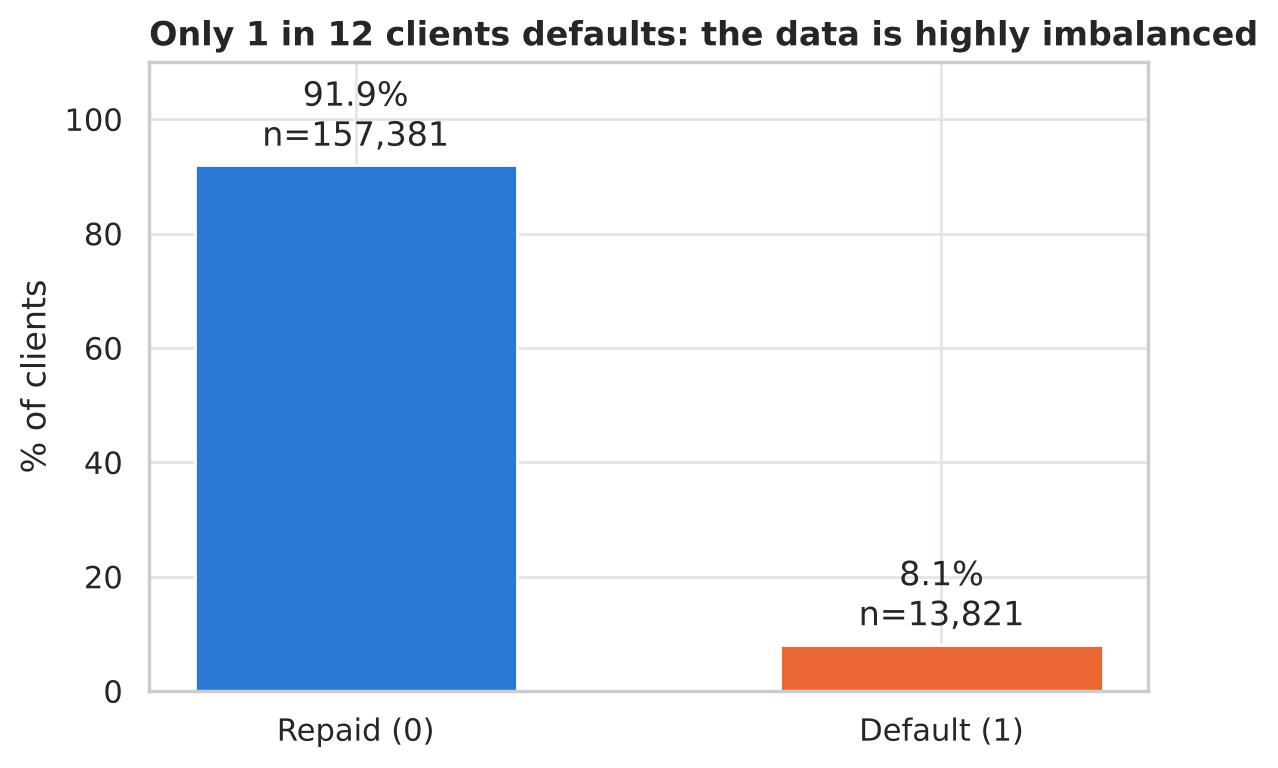

In [4]:
counts = train["TARGET"].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Repaid (0)", "Default (1)"], pct, color=[C_REPAID, C_DEFAULT], width=0.55)
ax.bar_label(bars, labels=[f"{p:.1f}%\nn={thousands(n)}" for p, n in zip(pct, counts)], padding=3)
ax.set_ylim(0, 110)
ax.set_ylabel("% of clients")
ax.set_title("Only 1 in 12 clients defaults: the data is highly imbalanced")
plt.tight_layout(); plt.show()

**What we see:** 91.9% repaid and 8.1% defaulted.

**Decision:**
- The metric is **AUC**, not accuracy: a model that said "everyone repays" would be 92% accurate and completely useless.
- Validate with **`StratifiedKFold`**, so every fold keeps the same 8% of defaults.
- In the following charts, always **rates** or normalised densities, never raw counts.

## 3. Which columns have missing values? Does being missing tell us something?

**Path in the tree:** compare categories (the columns) → more than 7 or long labels? **Yes** → **sorted horizontal bars**. We plot train and test together to check that values are missing in the same proportion.

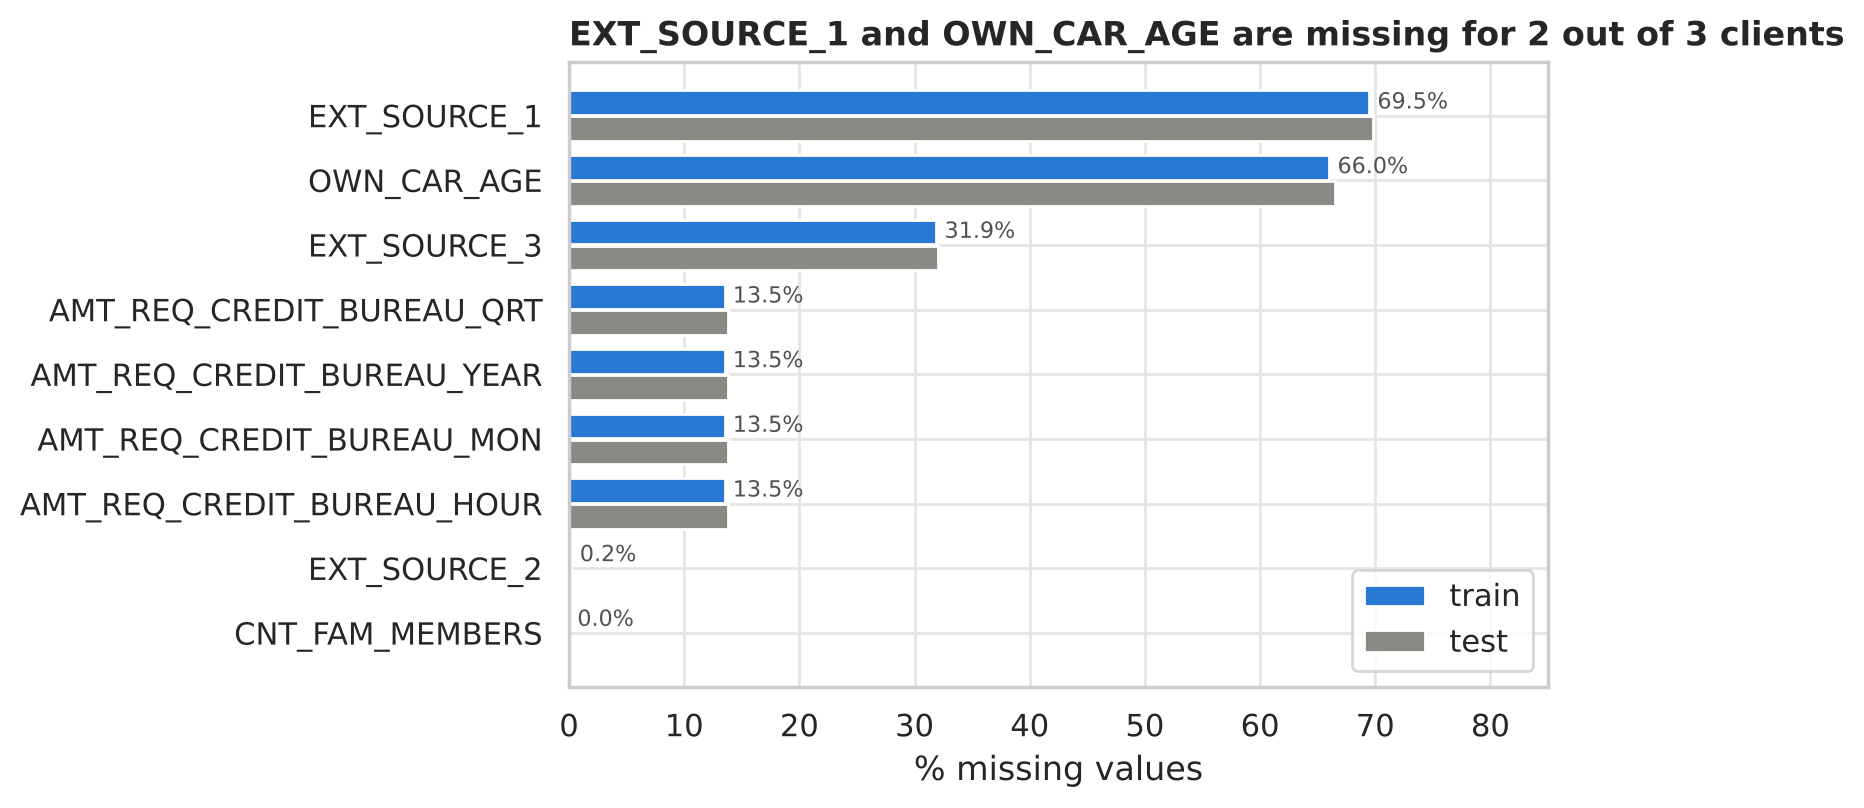

In [5]:
na = pd.DataFrame({"train": train.isna().mean() * 100,
                   "test": test.isna().mean() * 100}).dropna()
na = na[na["train"] > 0].sort_values("train")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(na))
b1 = ax.barh(y + 0.2, na["train"], height=0.38, color=C_ONE, label="train")
b2 = ax.barh(y - 0.2, na["test"], height=0.38, color=C_GREY, label="test")
ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.set_yticks(y, na.index)
ax.set_xlim(0, 85)
ax.set_xlabel("% missing values")
ax.set_title("EXT_SOURCE_1 and OWN_CAR_AGE are missing for 2 out of 3 clients")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

A missing value **is also information**. A real-life example: if someone leaves "years in current job" blank on a bank form, that already says something about them. We check whether the default rate changes when the value is missing.

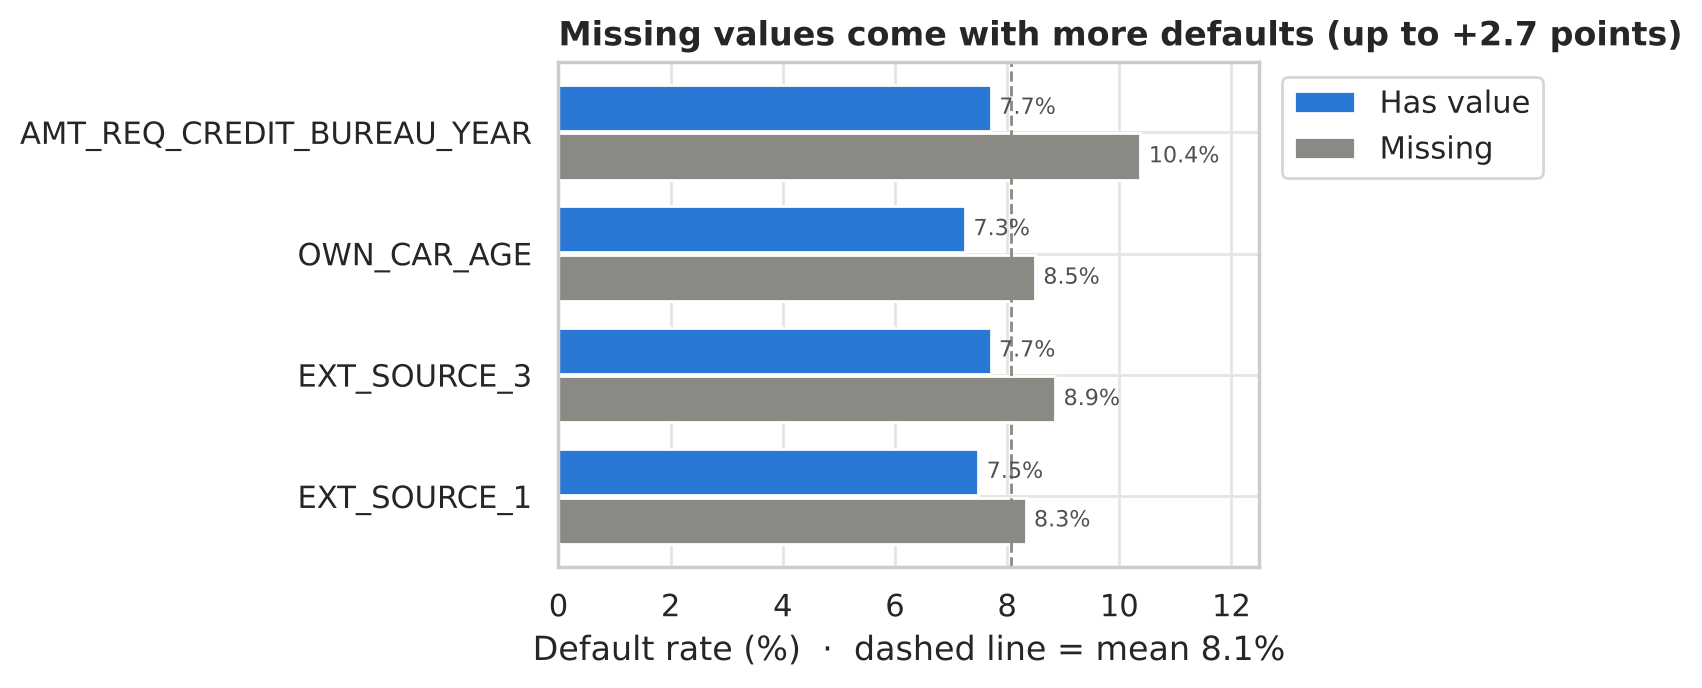

In [6]:
cols_na = ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "AMT_REQ_CREDIT_BUREAU_YEAR"]
t = pd.DataFrame({c: train.groupby(train[c].isna())["TARGET"].mean() * 100 for c in cols_na}).T
t.columns = ["Has value", "Missing"]

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(t))
b1 = ax.barh(y + 0.2, t["Has value"], height=0.38, color=C_ONE, label="Has value")
b2 = ax.barh(y - 0.2, t["Missing"], height=0.38, color=C_GREY, label="Missing")
for b in (b1, b2):
    ax.bar_label(b, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.axvline(MEAN_RATE * 100, color=C_GREY, ls="--", lw=1)
ax.set_yticks(y, t.index)
ax.set_xlim(0, 12.5)
ax.set_xlabel("Default rate (%)  ·  dashed line = mean 8.1%")
ax.set_title("Missing values come with more defaults (up to +2.7 points)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

**What we see:**
- The share of missing values is almost identical in train and test: both sets come from the same source.
- The four `AMT_REQ_CREDIT_BUREAU_*` columns are missing together (13.5%): they are one "block" of information.
- When the value is missing, the default rate goes up in every case: from 7.7% to **10.4%** for `AMT_REQ_CREDIT_BUREAU_*` (+2.7 points), and between +0.8 and +1.2 points for `EXT_SOURCE_1`, `EXT_SOURCE_3` and `OWN_CAR_AGE`.

**Decision:**
- **Do not impute with the mean** as the tutorial does: LightGBM handles `NaN` natively and can use the fact that a value is missing.
- Create **`N_MISSING`** (number of missing values per row) and **`EXT_SOURCE_N_MISSING`** in Phase 3.

## 4. Which numeric variables best separate repaid from default?

Before plotting 21 variables one by one, we build a **ranking**. For each variable we compute its **univariate AUC**: the AUC a "model" would get using only that variable to rank the clients.

> **Analogy:** it is like trying out each player on their own before picking the team. 0.50 = tossing a coin (useless); the closer to 1, the better the variable separates on its own.

**Path in the tree:** compare many categories (the variables) → **sorted horizontal bars**. The bars start at 0.50 (chance), not at 0.

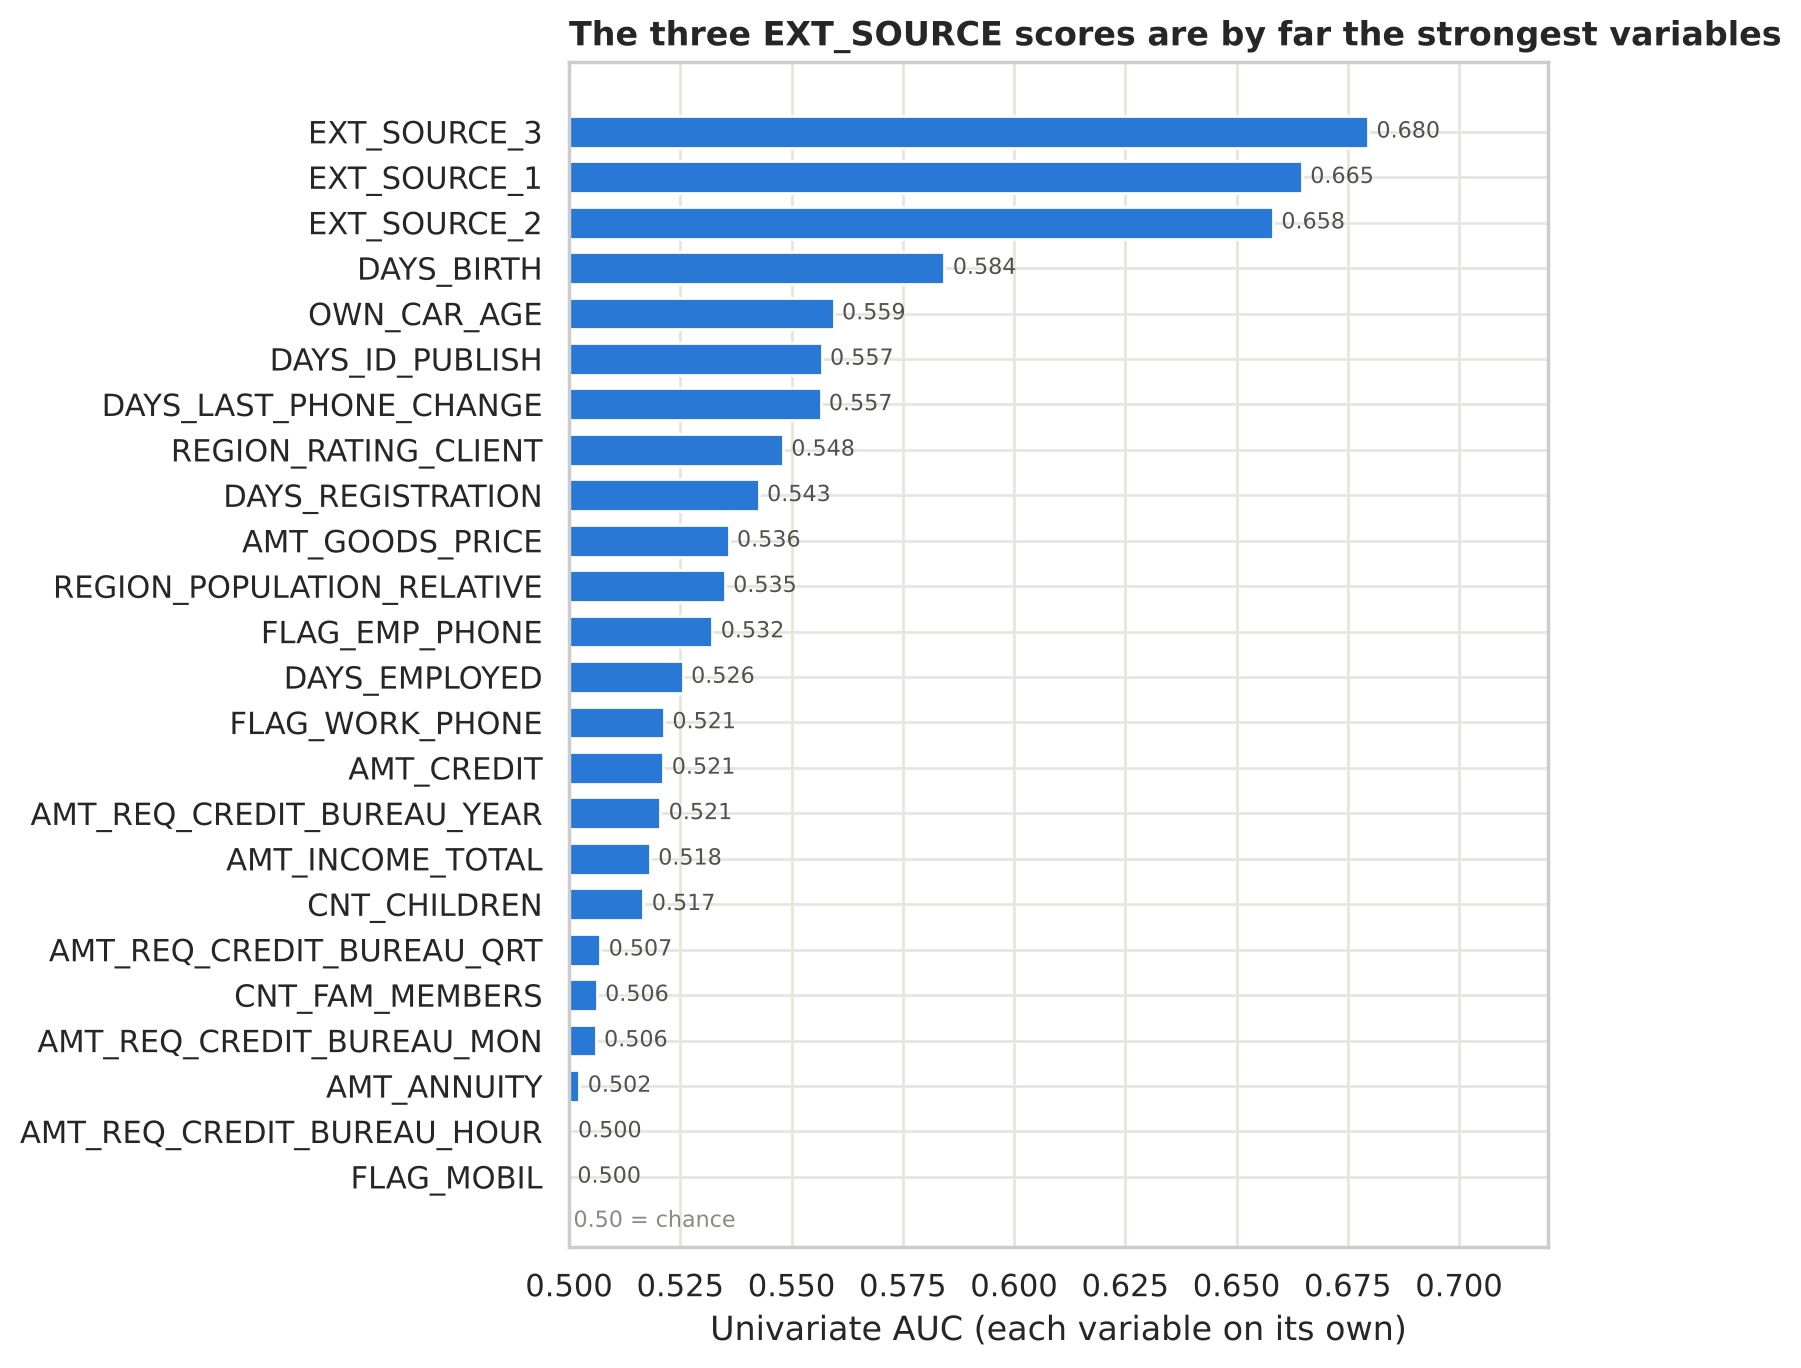

In [7]:
auc_uni = {}
for c in num_all:
    m = train[c].notna()
    a = roc_auc_score(train.loc[m, "TARGET"], train.loc[m, c])
    auc_uni[c] = max(a, 1 - a)          # direct or inverse relationship, both count
auc_uni = pd.Series(auc_uni).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.barh(auc_uni.index, auc_uni.values - 0.5, left=0.5, color=C_ONE, height=0.7)  # bars start at 0.50 (chance)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in auc_uni.values], padding=3, fontsize=8, color="#52514e")
ax.axvline(0.5, color=C_GREY, ls="--", lw=1)
ax.text(0.501, -1.1, "0.50 = chance", color=C_GREY, fontsize=8)
ax.set_xlim(0.5, 0.72)
ax.set_xlabel("Univariate AUC (each variable on its own)")
ax.set_title("The three EXT_SOURCE scores are by far the strongest variables")
plt.tight_layout(); plt.show()

**What we see:**
- `EXT_SOURCE_3` (0.680), `EXT_SOURCE_1` (0.665) and `EXT_SOURCE_2` (0.658) are well above the rest.
- Age comes next (`DAYS_BIRTH`, 0.584).
- The amounts (`AMT_CREDIT`, `AMT_ANNUITY`, `AMT_INCOME_TOTAL`) hardly separate **on their own**. That does not make them useless: a banker does not only look at how much you ask for, but at how much you ask for **relative to** what you earn. Hence the ratios in Phase 3.
- `FLAG_MOBIL` and `AMT_REQ_CREDIT_BUREAU_HOUR` ≈ 0.50: they add nothing.

**Decision:** focus on combining the `EXT_SOURCE` scores (mean, min, max, product) and on amount ratios.

## 5. The EXT_SOURCE scores: how do they separate?

**Path in the tree:** distribution of one numeric variable → compare it across groups? **Yes** (repaid / default) → few data points per group? **No** → does the full shape matter? **Yes** → violin, or its "lying down" version: **overlapping densities (KDE)**. Three variables on the same axes → **small multiples**.

⚠️ `common_norm=False` is essential: each curve gets an area of 1 on its own. Without it, the default curve is squashed because defaults are only 8% of the data.

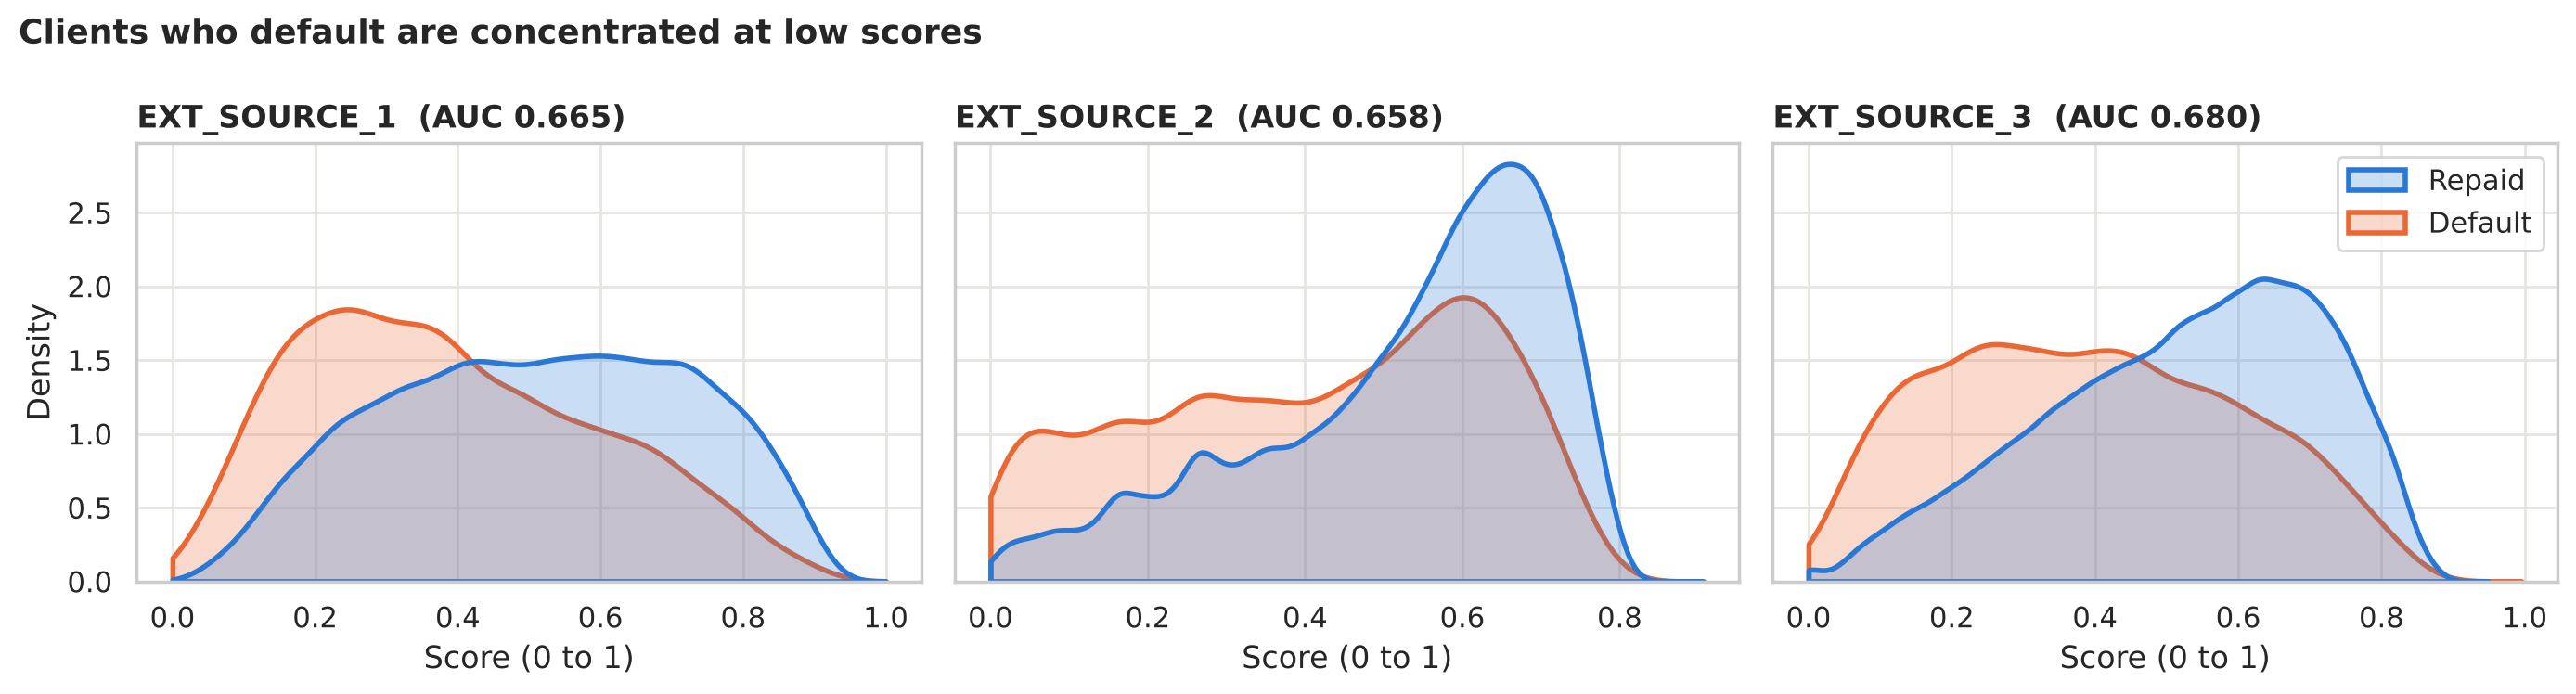

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, c in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=vis, x=c, hue="STATUS", hue_order=["Repaid", "Default"], palette=TARGET_PALETTE,
                common_norm=False, fill=True, alpha=0.25, linewidth=2, ax=ax, clip=(0, 1))
    ax.set_title(f"{c}  (AUC {auc_uni[c]:.3f})")
    ax.set_xlabel("Score (0 to 1)"); ax.set_ylabel("Density")
    if ax is not axes[-1]:
        ax.get_legend().remove()
    else:
        sns.move_legend(ax, "upper right", title=None)
fig.suptitle("Clients who default are concentrated at low scores", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**What we see:** in all three, the orange curve (default) is shifted to the left: **low score = higher risk**. The curves overlap a lot, so none of them is enough on its own; combined they work better.

**Decision (Phase 3):** `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_STD`, `EXT_PROD` (computed with the available scores when one is missing).

## 6. Does risk change with age?

`DAYS_BIRTH` is in negative days (counted back from the application date). We convert it to years, split it into **10 bins with the same number of clients** (`pd.qcut`) and compute the default rate in each bin.

> **Why bins and not a scatter plot:** `TARGET` is only 0 or 1, so a scatter plot would be two horizontal lines. Binning is like looking at the average grade per class instead of each student's grade.

**Path in the tree:** categories (the bins) → more than 7? There are 10, but with short labels and a natural order → **vertical bars**, without re-sorting (the age order is the message).

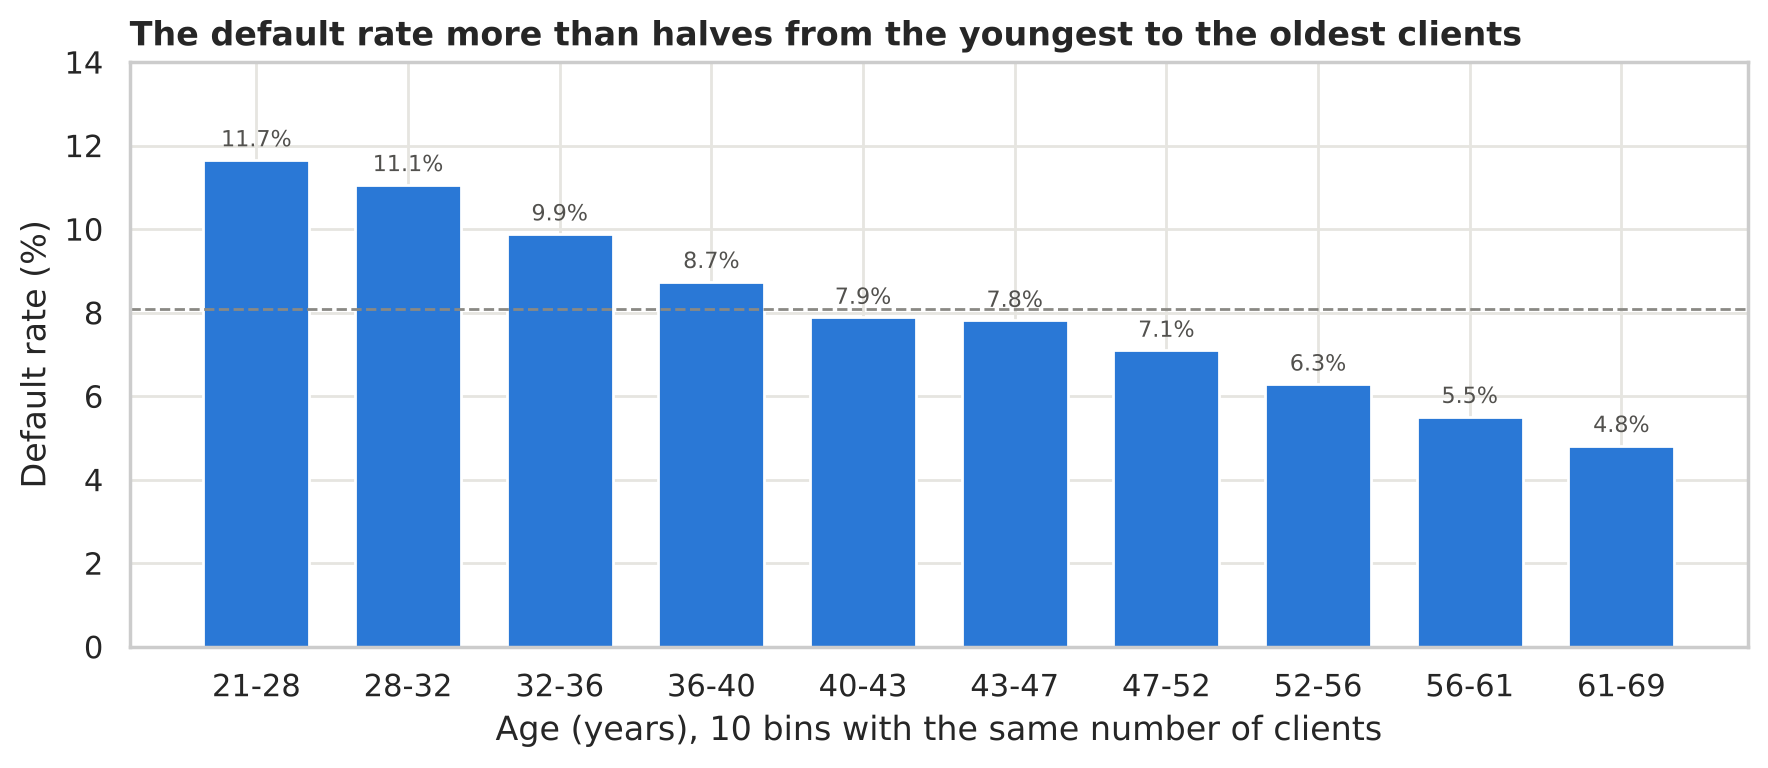

In [9]:
age = -train["DAYS_BIRTH"] / 365.25
age_bin = pd.qcut(age, 10)
g = train.groupby(age_bin, observed=True)["TARGET"].mean() * 100
labels = [f"{iv.left:.0f}-{iv.right:.0f}" for iv in g.index]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, g.values, color=C_ONE, width=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.axhline(MEAN_RATE * 100, color=C_GREY, ls="--", lw=1)
ax.set_ylim(0, 14)
ax.set_xlabel("Age (years), 10 bins with the same number of clients")
ax.set_ylabel("Default rate (%)")
ax.set_title("The default rate more than halves from the youngest to the oldest clients")
plt.tight_layout(); plt.show()

**What we see:** the rate falls very steadily, from 11.7% (ages 21-28) to 4.8% (ages 61-69). It is a **monotonic** relationship: the older the client, the lower the risk.

**Decision:** create `AGE_YEARS` (more readable; the scale does not matter to LightGBM). Try `EMPLOYED_BIRTH_RATIO` (share of their life spent working) in Phase 3.

## 7. The DAYS_EMPLOYED anomaly

**Path in the tree:** distribution of one numeric variable, no groups → need to read percentiles? **No** → **histogram**. The histogram is the "oddity detector": an isolated spike far from the rest is almost always a code, not real data.

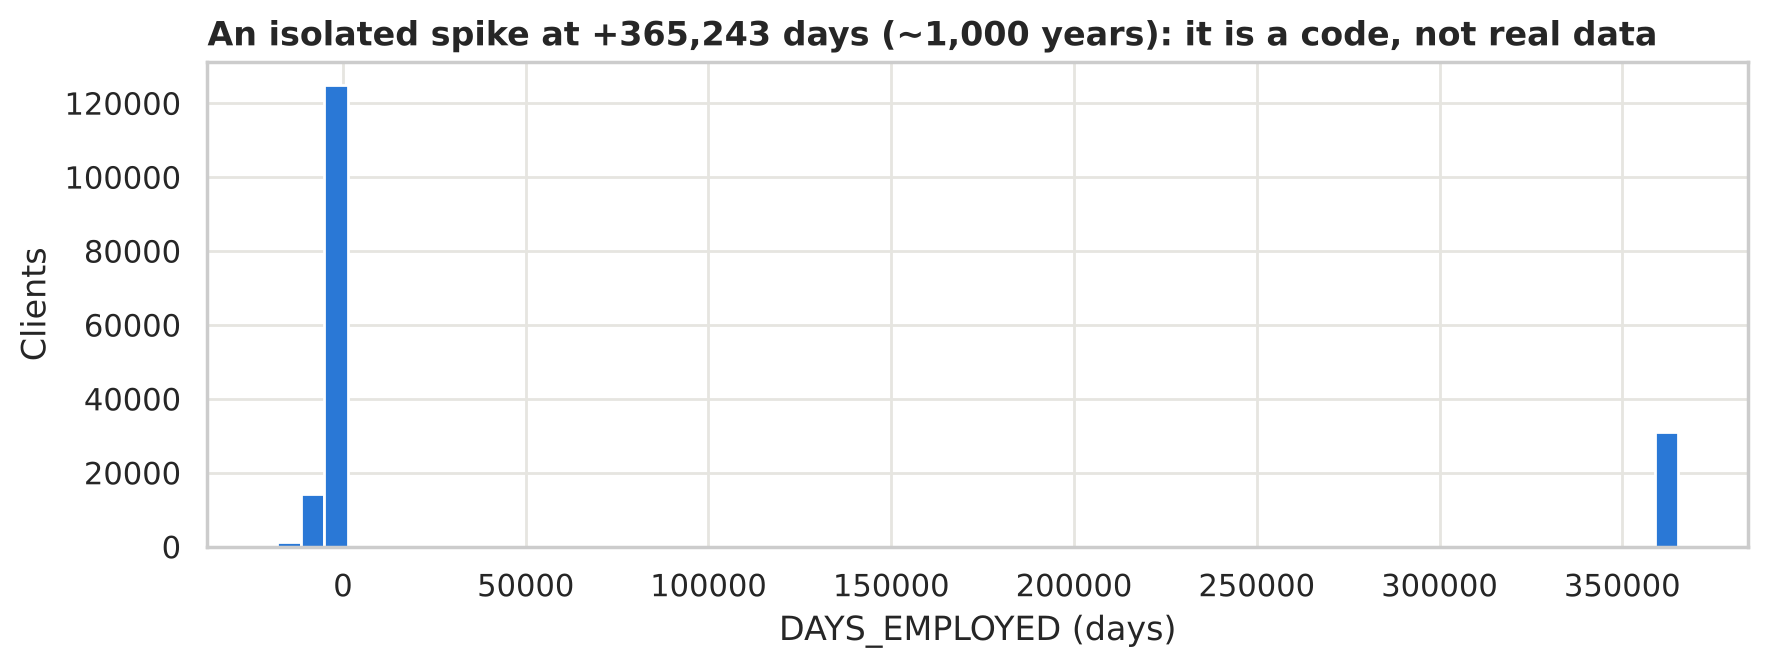

Clients with code 365243: 30,898 (18.0%)


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(train["DAYS_EMPLOYED"], bins=60, color=C_ONE)
ax.set_xlabel("DAYS_EMPLOYED (days)")
ax.set_ylabel("Clients")
ax.set_title("An isolated spike at +365,243 days (~1,000 years): it is a code, not real data")
plt.tight_layout(); plt.show()

anom = train["DAYS_EMPLOYED"] == 365243
print(f"Clients with code 365243: {thousands(anom.sum())} ({anom.mean():.1%})")

Who are these clients? We cross the anomaly with the income type and with `FLAG_EMP_PHONE`:

In [11]:
display(pd.crosstab(anom.rename("DAYS_EMPLOYED = 365243"), train["NAME_INCOME_TYPE"]))
display(pd.crosstab(anom.rename("DAYS_EMPLOYED = 365243"), train["FLAG_EMP_PHONE"]))

NAME_INCOME_TYPE,Businessman,Commercial associate,Maternity leave,Pensioner,State servant,Student,Unemployed,Working
DAYS_EMPLOYED = 365243,,,,,,,,
False,3,40007,3,7,12007,9,0,88268
True,0,0,0,30888,0,0,10,0


FLAG_EMP_PHONE,0,1
DAYS_EMPLOYED = 365243,,
False,5,140299
True,30898,0


**Path in the tree** to compare the rate: categories, 2 groups → **bars**.

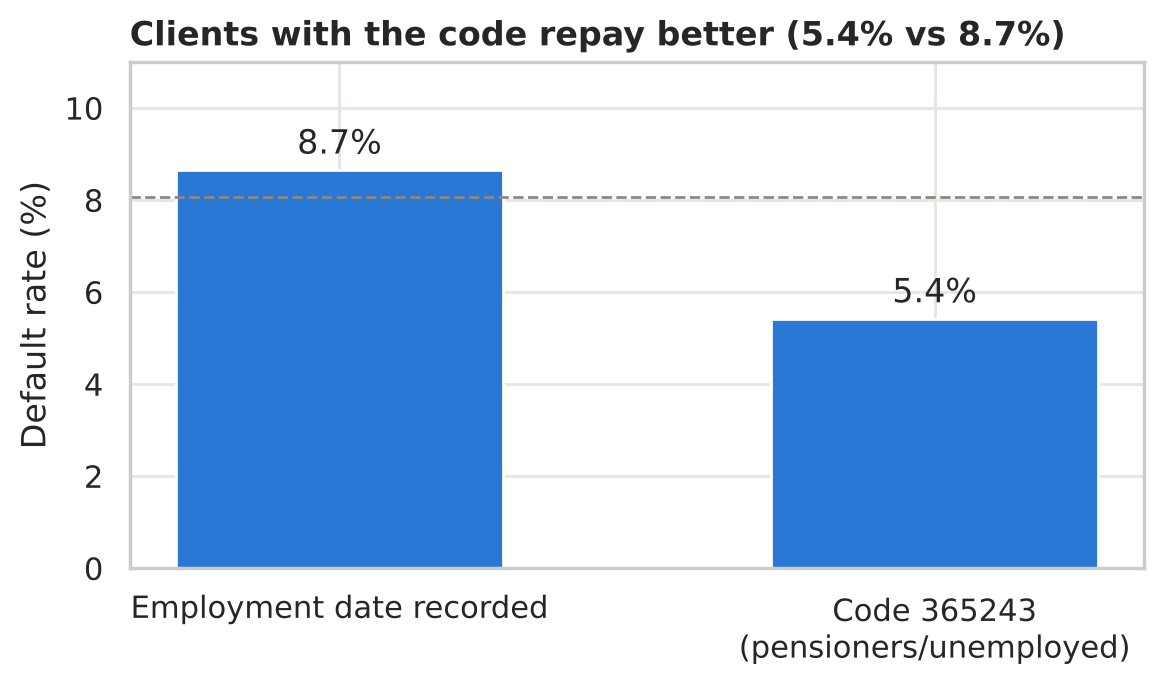

In [12]:
t = train.groupby(anom)["TARGET"].mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["Employment date recorded", "Code 365243\n(pensioners/unemployed)"],
              t.values, color=C_ONE, width=0.55)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(MEAN_RATE * 100, color=C_GREY, ls="--", lw=1)
ax.set_ylim(0, 11)
ax.set_ylabel("Default rate (%)")
ax.set_title("Clients with the code repay better (5.4% vs 8.7%)")
plt.tight_layout(); plt.show()

**What we see:**
- 18% of clients have `DAYS_EMPLOYED = 365243`. **They are exactly the pensioners (plus the 10 unemployed clients)**: the bank has no employment date for them and stores this code instead.
- These clients are lower risk (5.4%).
- `FLAG_EMP_PHONE = 0` matches the anomaly almost perfectly (30,898 out of 30,903 cases): **two columns saying the same thing**.

**Decision (Phase 2):**
- `DAYS_EMPLOYED == 365243` → `NaN`, and create the flag **`DAYS_EMPLOYED_ANOM`**.
- Try dropping `FLAG_EMP_PHONE` as redundant (check with the validation AUC).

## 8. The amounts: income, credit, annuity, goods price

**Path in the tree:** one numeric variable compared across groups → lots of data → does the full shape matter? **No**, we want to compare medians and see outliers → **boxplot**. The amounts have very long tails (one client earns 13.5 million), so we use a **log scale**: without it the box is squashed against the floor.

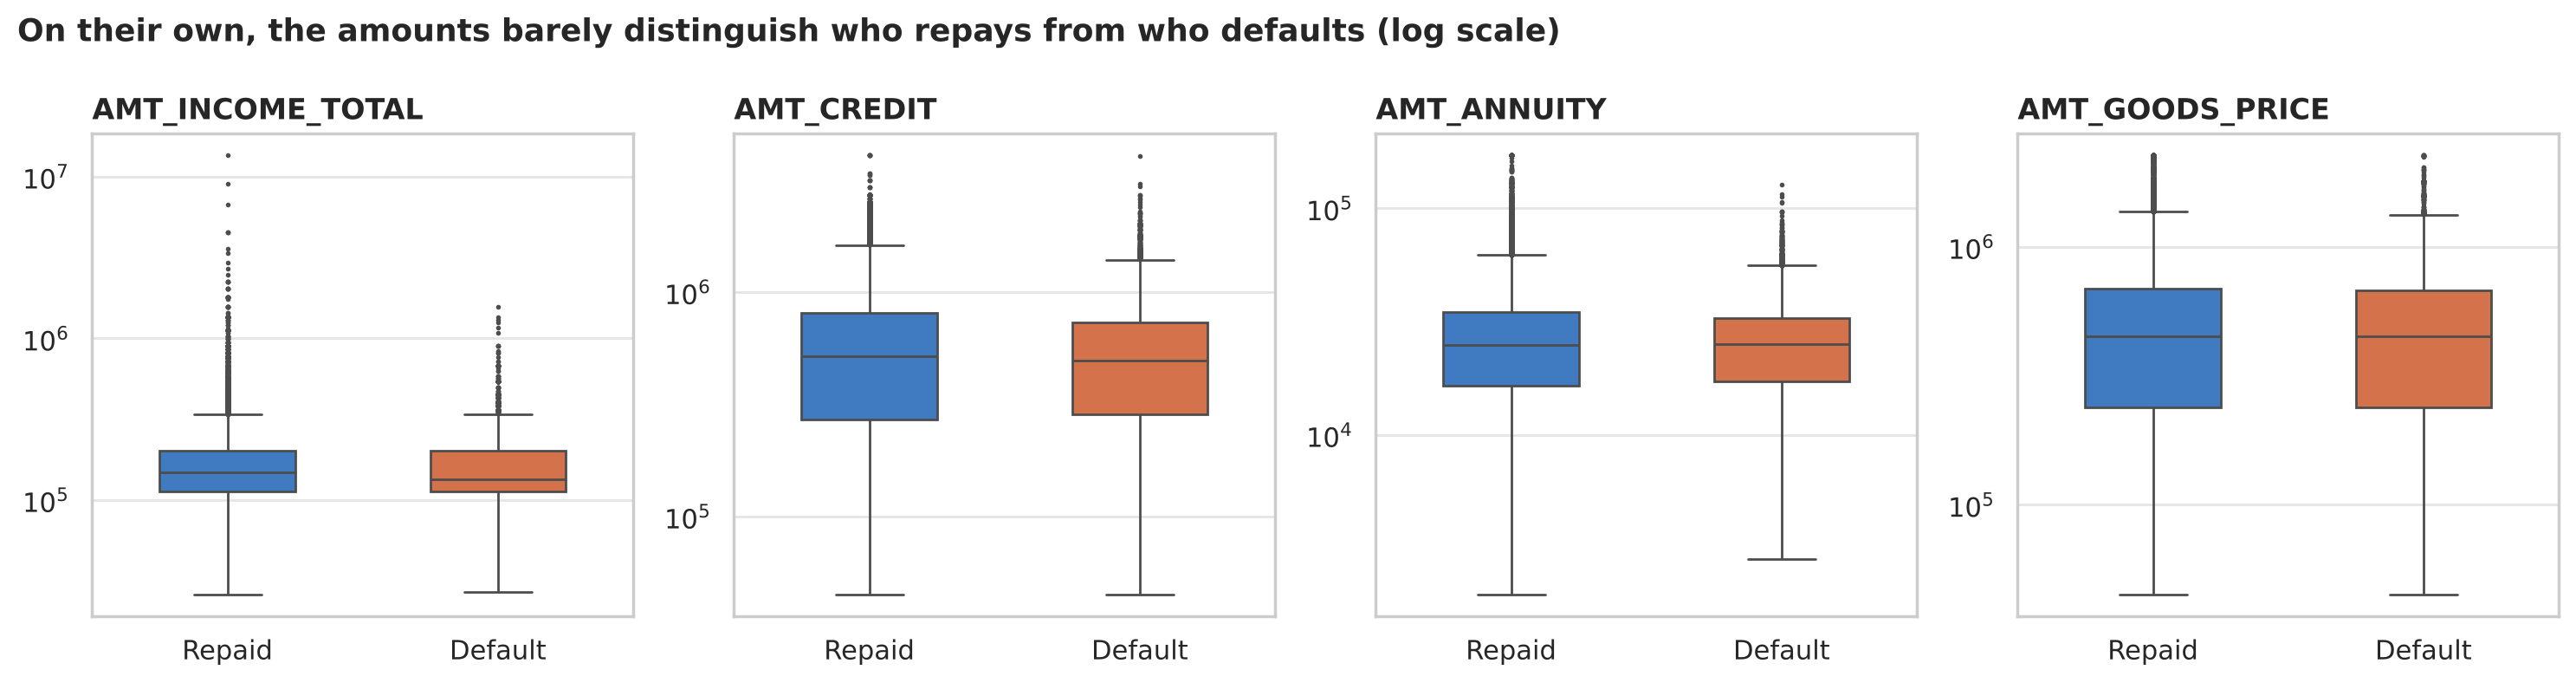

In [13]:
amt = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, c in zip(axes, amt):
    sns.boxplot(data=vis, x="STATUS", y=c, hue="STATUS", order=["Repaid", "Default"],
                palette=TARGET_PALETTE, ax=ax, width=0.5, fliersize=1, legend=False)
    ax.set_yscale("log")
    ax.set_title(c)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("On their own, the amounts barely distinguish who repays from who defaults (log scale)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**Are there variables that say almost the same thing?** `AMT_CREDIT` (amount lent) and `AMT_GOODS_PRICE` (price of the goods bought) should move together.

**Path in the tree:** relationship between two numeric variables → more than about 2,000 points? **Yes** (171,202) → **hexbin**. A scatter plot would be a solid black blob.

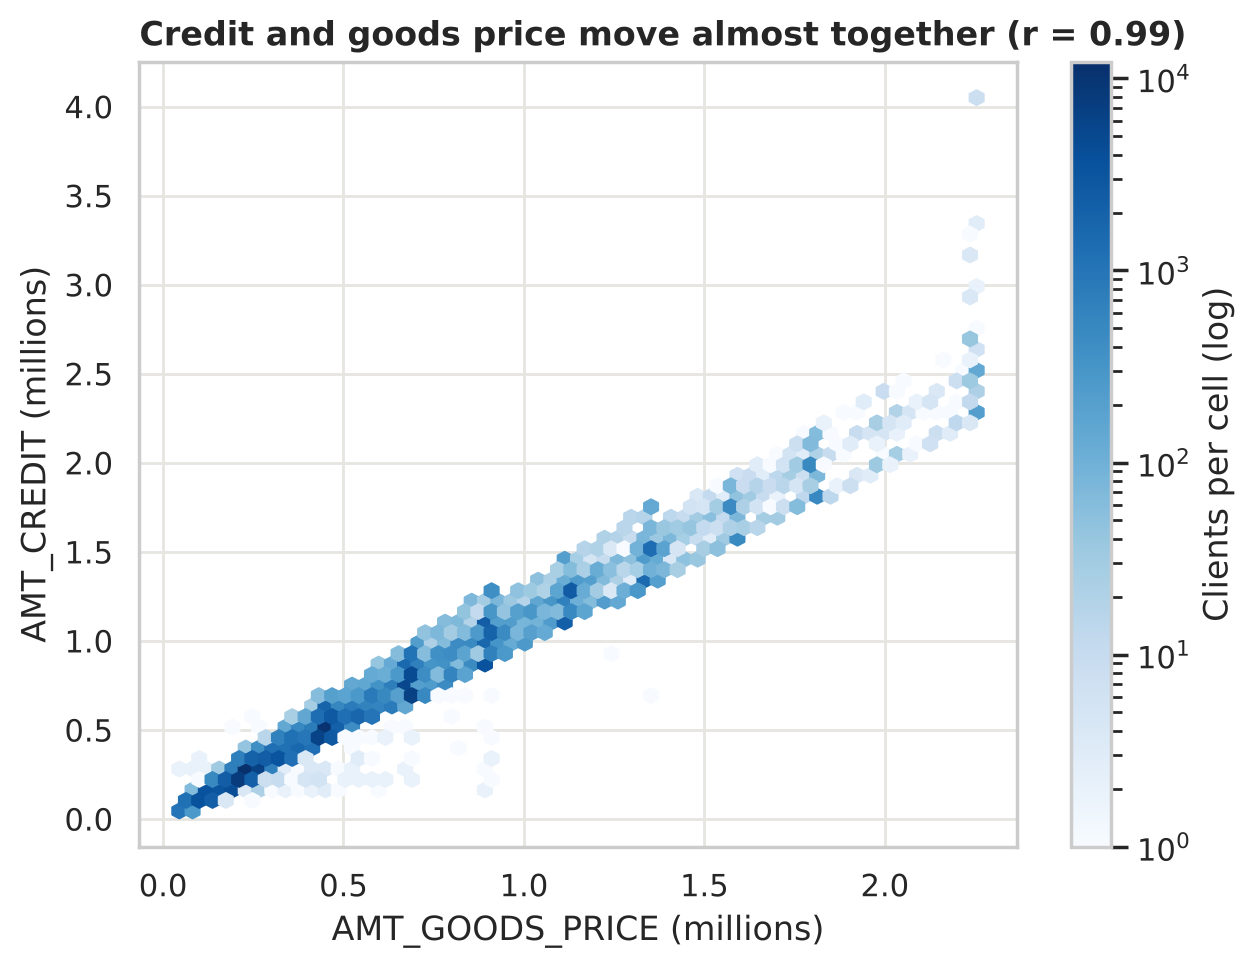

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(train["AMT_GOODS_PRICE"] / 1e6, train["AMT_CREDIT"] / 1e6, gridsize=60,
               cmap="Blues", bins="log", mincnt=1)
fig.colorbar(hb, ax=ax, label="Clients per cell (log)")
ax.set_xlabel("AMT_GOODS_PRICE (millions)")
ax.set_ylabel("AMT_CREDIT (millions)")
r = train[["AMT_GOODS_PRICE", "AMT_CREDIT"]].corr().iloc[0, 1]
ax.set_title(f"Credit and goods price move almost together (r = {r:.2f})")
plt.tight_layout(); plt.show()

**What we see:**
- The repaid and default boxes sit at almost the same height: **on their own**, the amounts do not separate (confirmed by the ranking in section 4).
- Credit and goods price have r = 0.99: almost the same information. What is interesting is **the gap between them** (borrowing more than the goods cost).
- `AMT_INCOME_TOTAL` has huge outliers, but LightGBM is not affected by them (it works with split points, not distances).

**Decision (Phase 3):** ratios `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO`, `CREDIT_TERM`, `GOODS_CREDIT_RATIO`. No outlier treatment needed for LightGBM (it would be needed for Logistic Regression).

**OWN_CAR_AGE.** The tutorial cuts at 60 years. Let's look at the high values one by one:

In [15]:
print(train["OWN_CAR_AGE"].value_counts().sort_index().tail(10))

OWN_CAR_AGE
44.0      11
45.0       5
46.0       3
49.0       4
54.0       5
55.0       1
57.0       1
64.0    1331
65.0     494
91.0       1
Name: count, dtype: int64


**What we see:** there are almost no cars aged 46 to 63, and then suddenly **1,331 cars aged 64 and 494 aged 65**. As with `DAYS_EMPLOYED`, these look like **codes**, not real ages.

**Decision (Phase 2):** `OWN_CAR_AGE >= 64` → `NaN` + flag `OWN_CAR_AGE_ANOM`. Do not turn it into one-hot groups as the tutorial does: LightGBM uses it better as a number.

## 9. Categorical variables with few categories: which ones change the risk?

**Path in the tree:** compare categories → more than 7 **or long labels**? **Yes** (labels such as "Secondary / secondary special") → **horizontal bars sorted** by rate. Six variables on the same scale → **small multiples**.

Categories with fewer than 100 clients are hidden, because their rate is not reliable.

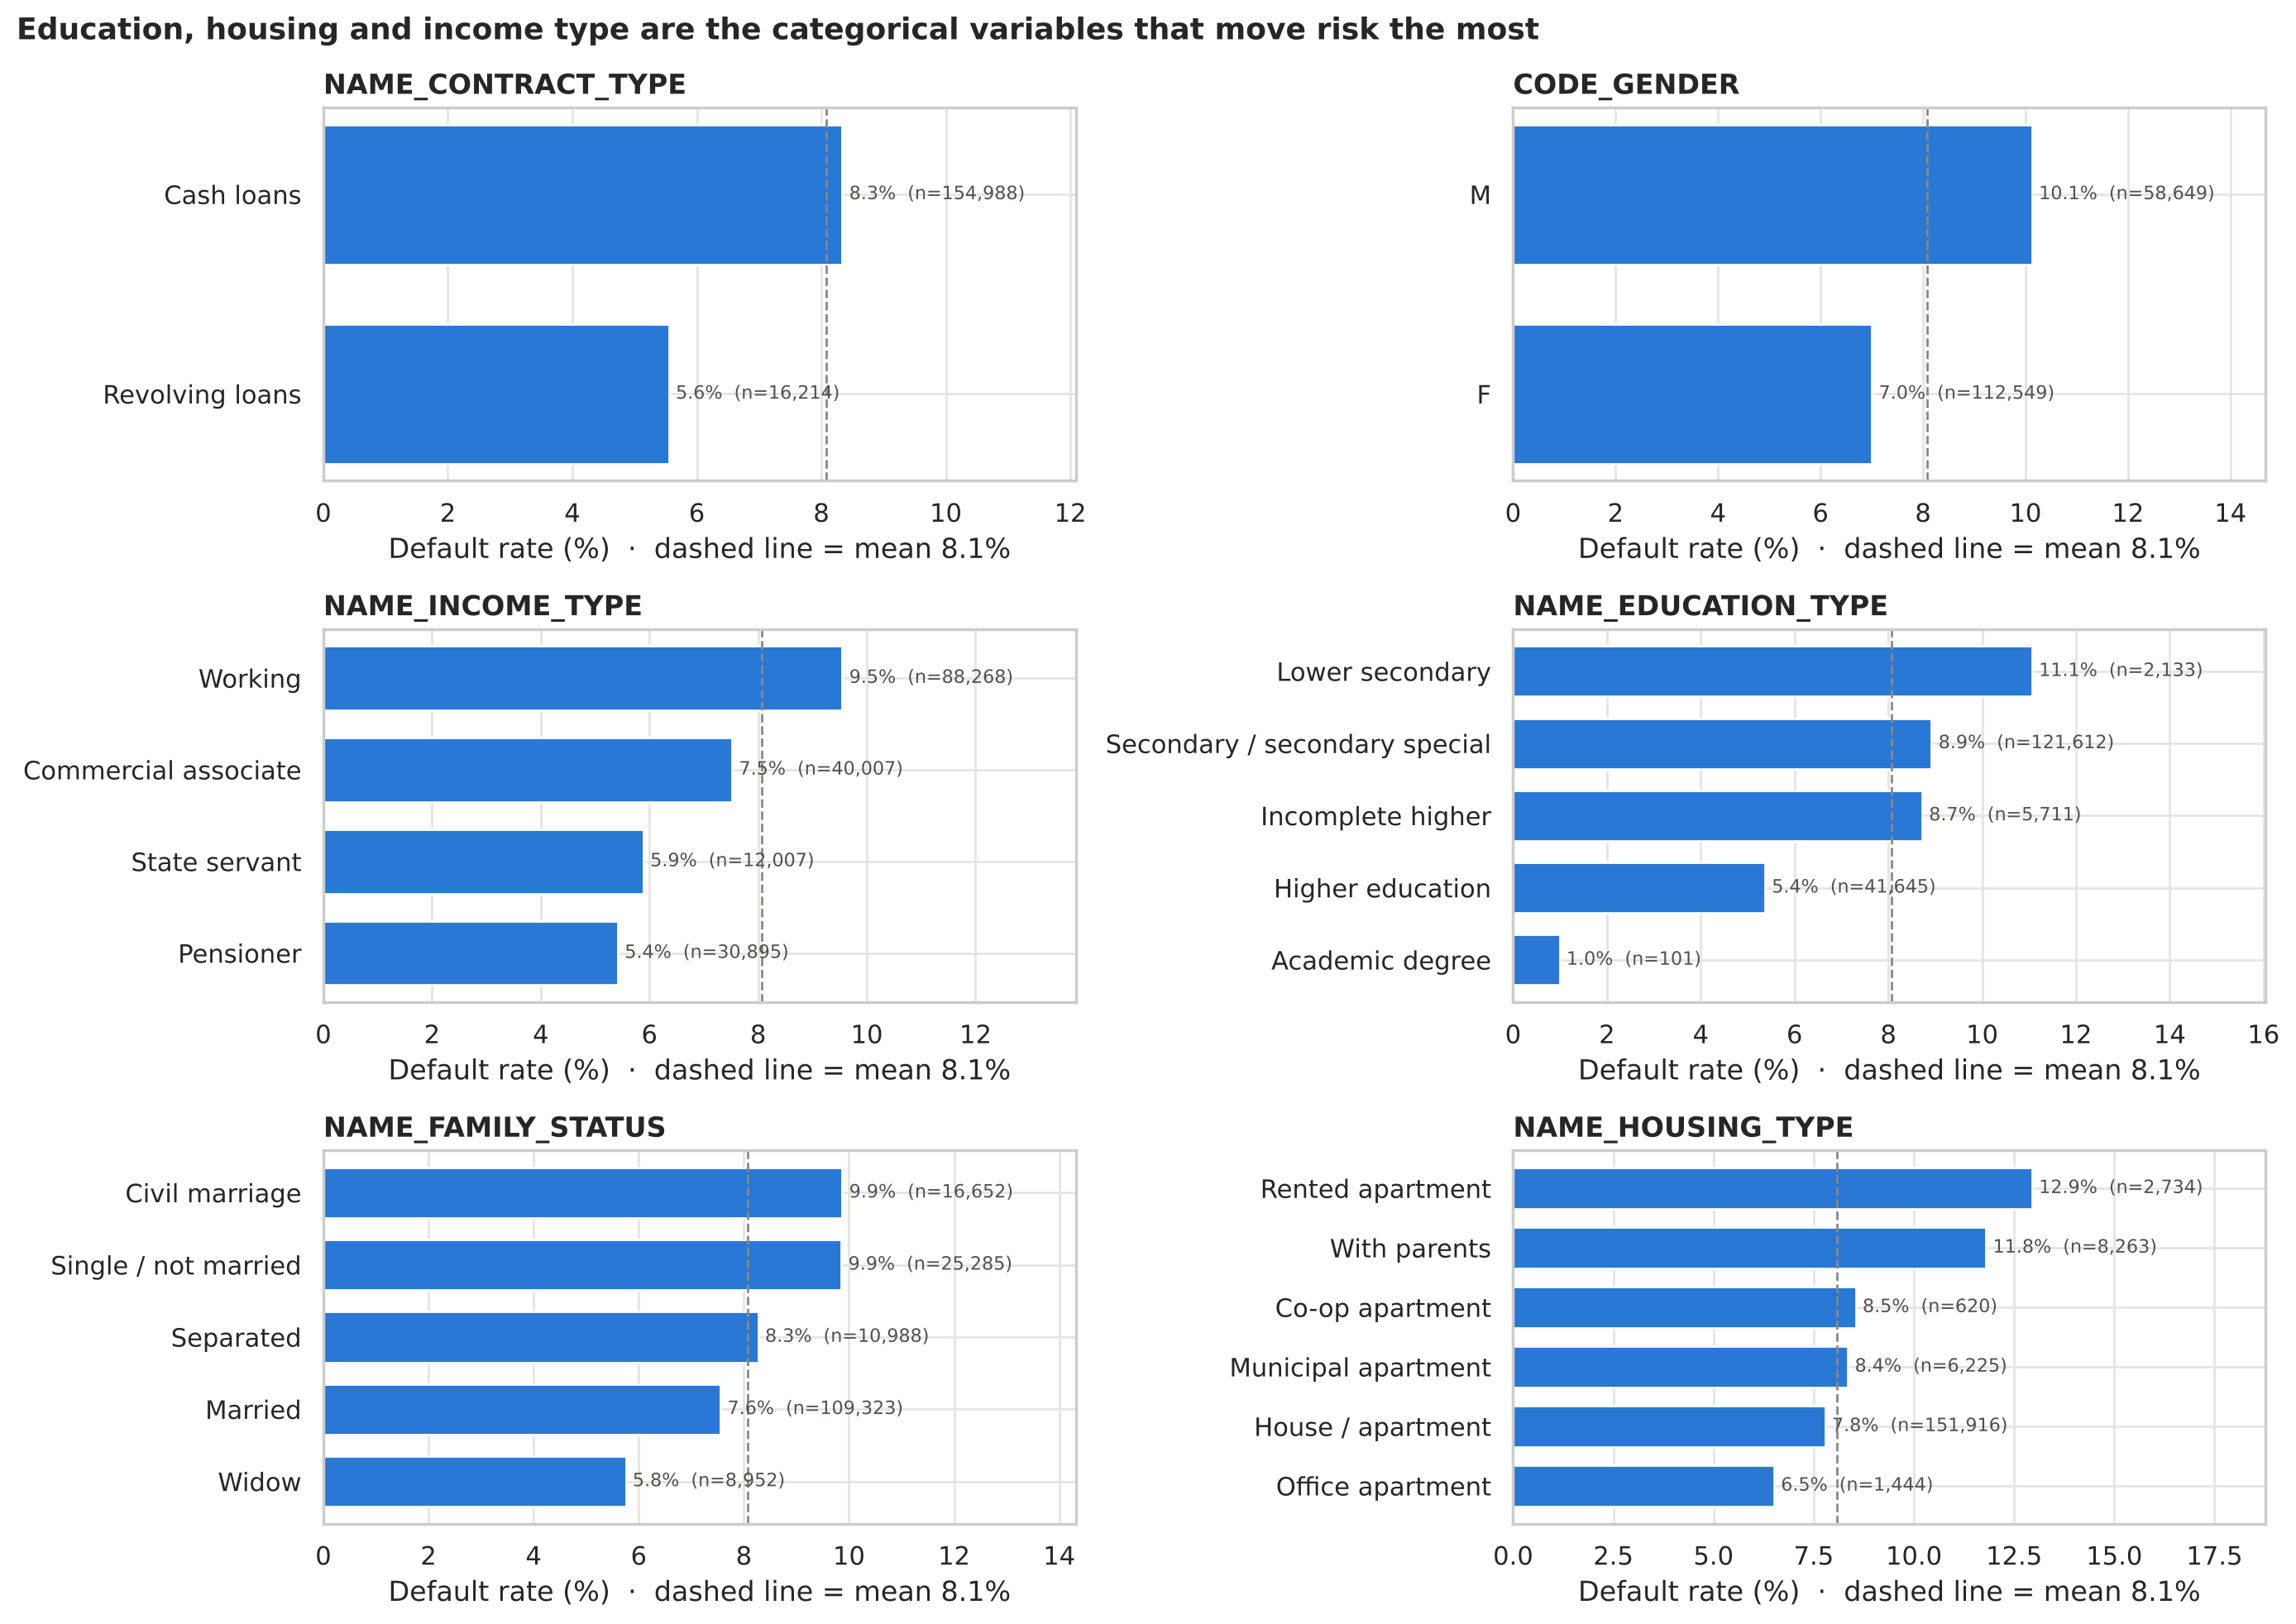

In [16]:
few = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
       "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE"]
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for ax, c in zip(axes.ravel(), few):
    rate_bars(c, ax)
fig.suptitle("Education, housing and income type are the categorical variables that move risk the most",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**What we see:**
- **Education:** from 5.4% (higher education) to 11.1% (lower secondary).
- **Housing:** renters (12.9%) and clients living with their parents (11.8%) are riskier.
- **Income type:** pensioners (5.4%) and state servants (5.9%) vs working (9.5%).
- **Gender:** men 10.1% vs women 7.0%.
- **Contract:** revolving 5.6% vs cash 8.3%.
- Nearly empty categories: `CODE_GENDER = "XNA"` (4 rows), `NAME_FAMILY_STATUS = "Unknown"` (2), and in `NAME_INCOME_TYPE`: Businessman (3), Student (9), Unemployed (10), Maternity leave (3).

**Decision (Phase 2):** `"XNA"` and `"Unknown"` → `NaN`. Encode the categorical variables with LightGBM's `category` type. Watch out for tiny categories: the model could memorise them.

## 10. Categorical variables with many categories: occupation and organisation

**Path in the tree:** compare categories → more than 7? **Yes** (19 and 58) → **sorted horizontal bars**. This is the most important fix compared with the tutorial, which used a 30 × 10 inch vertical `countplot` with unreadable labels and counts instead of rates.

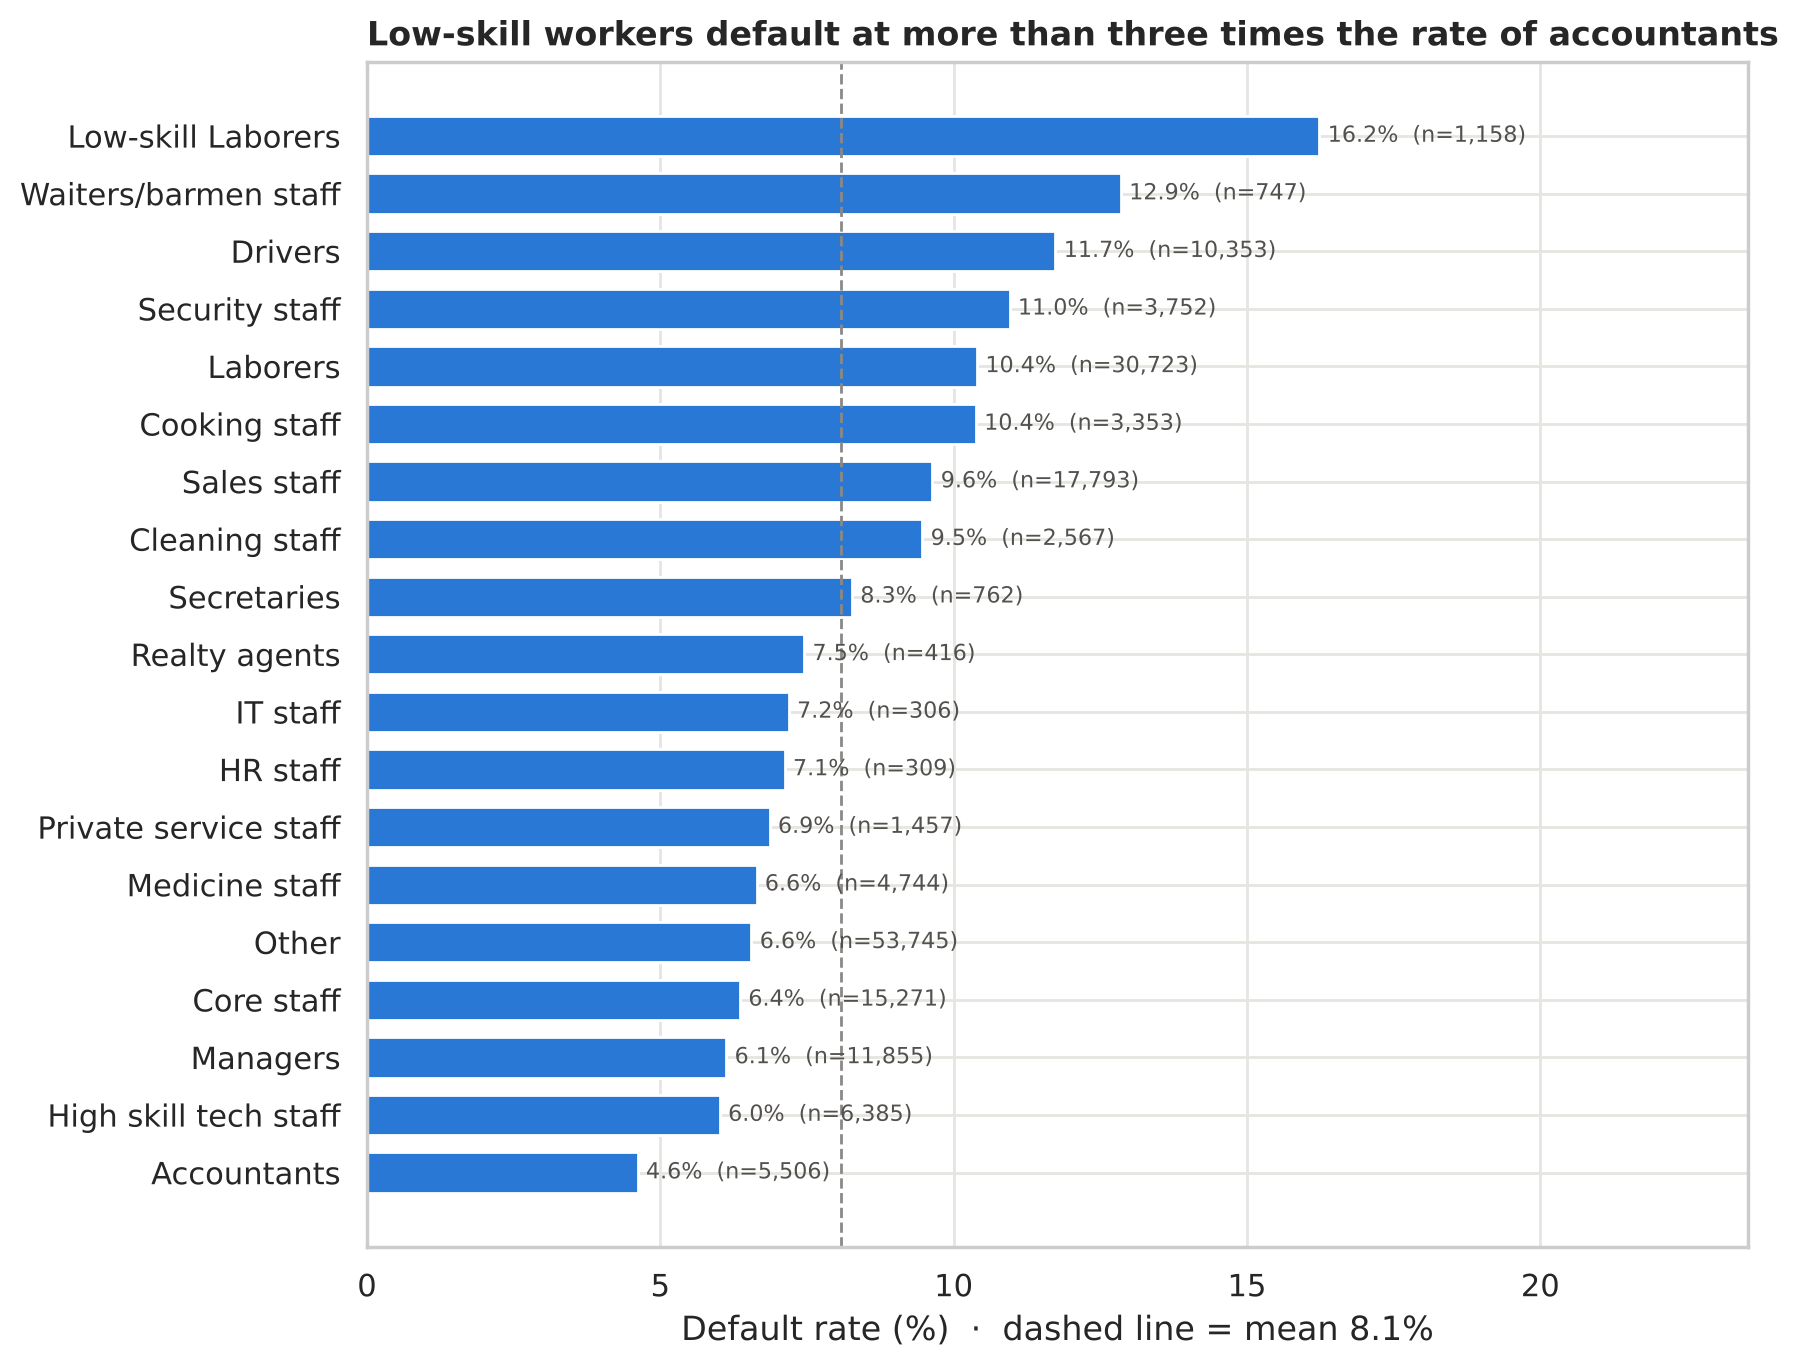

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
rate_bars("OCCUPATION_TYPE", ax,
          title="Low-skill workers default at more than three times the rate of accountants")
plt.tight_layout(); plt.show()

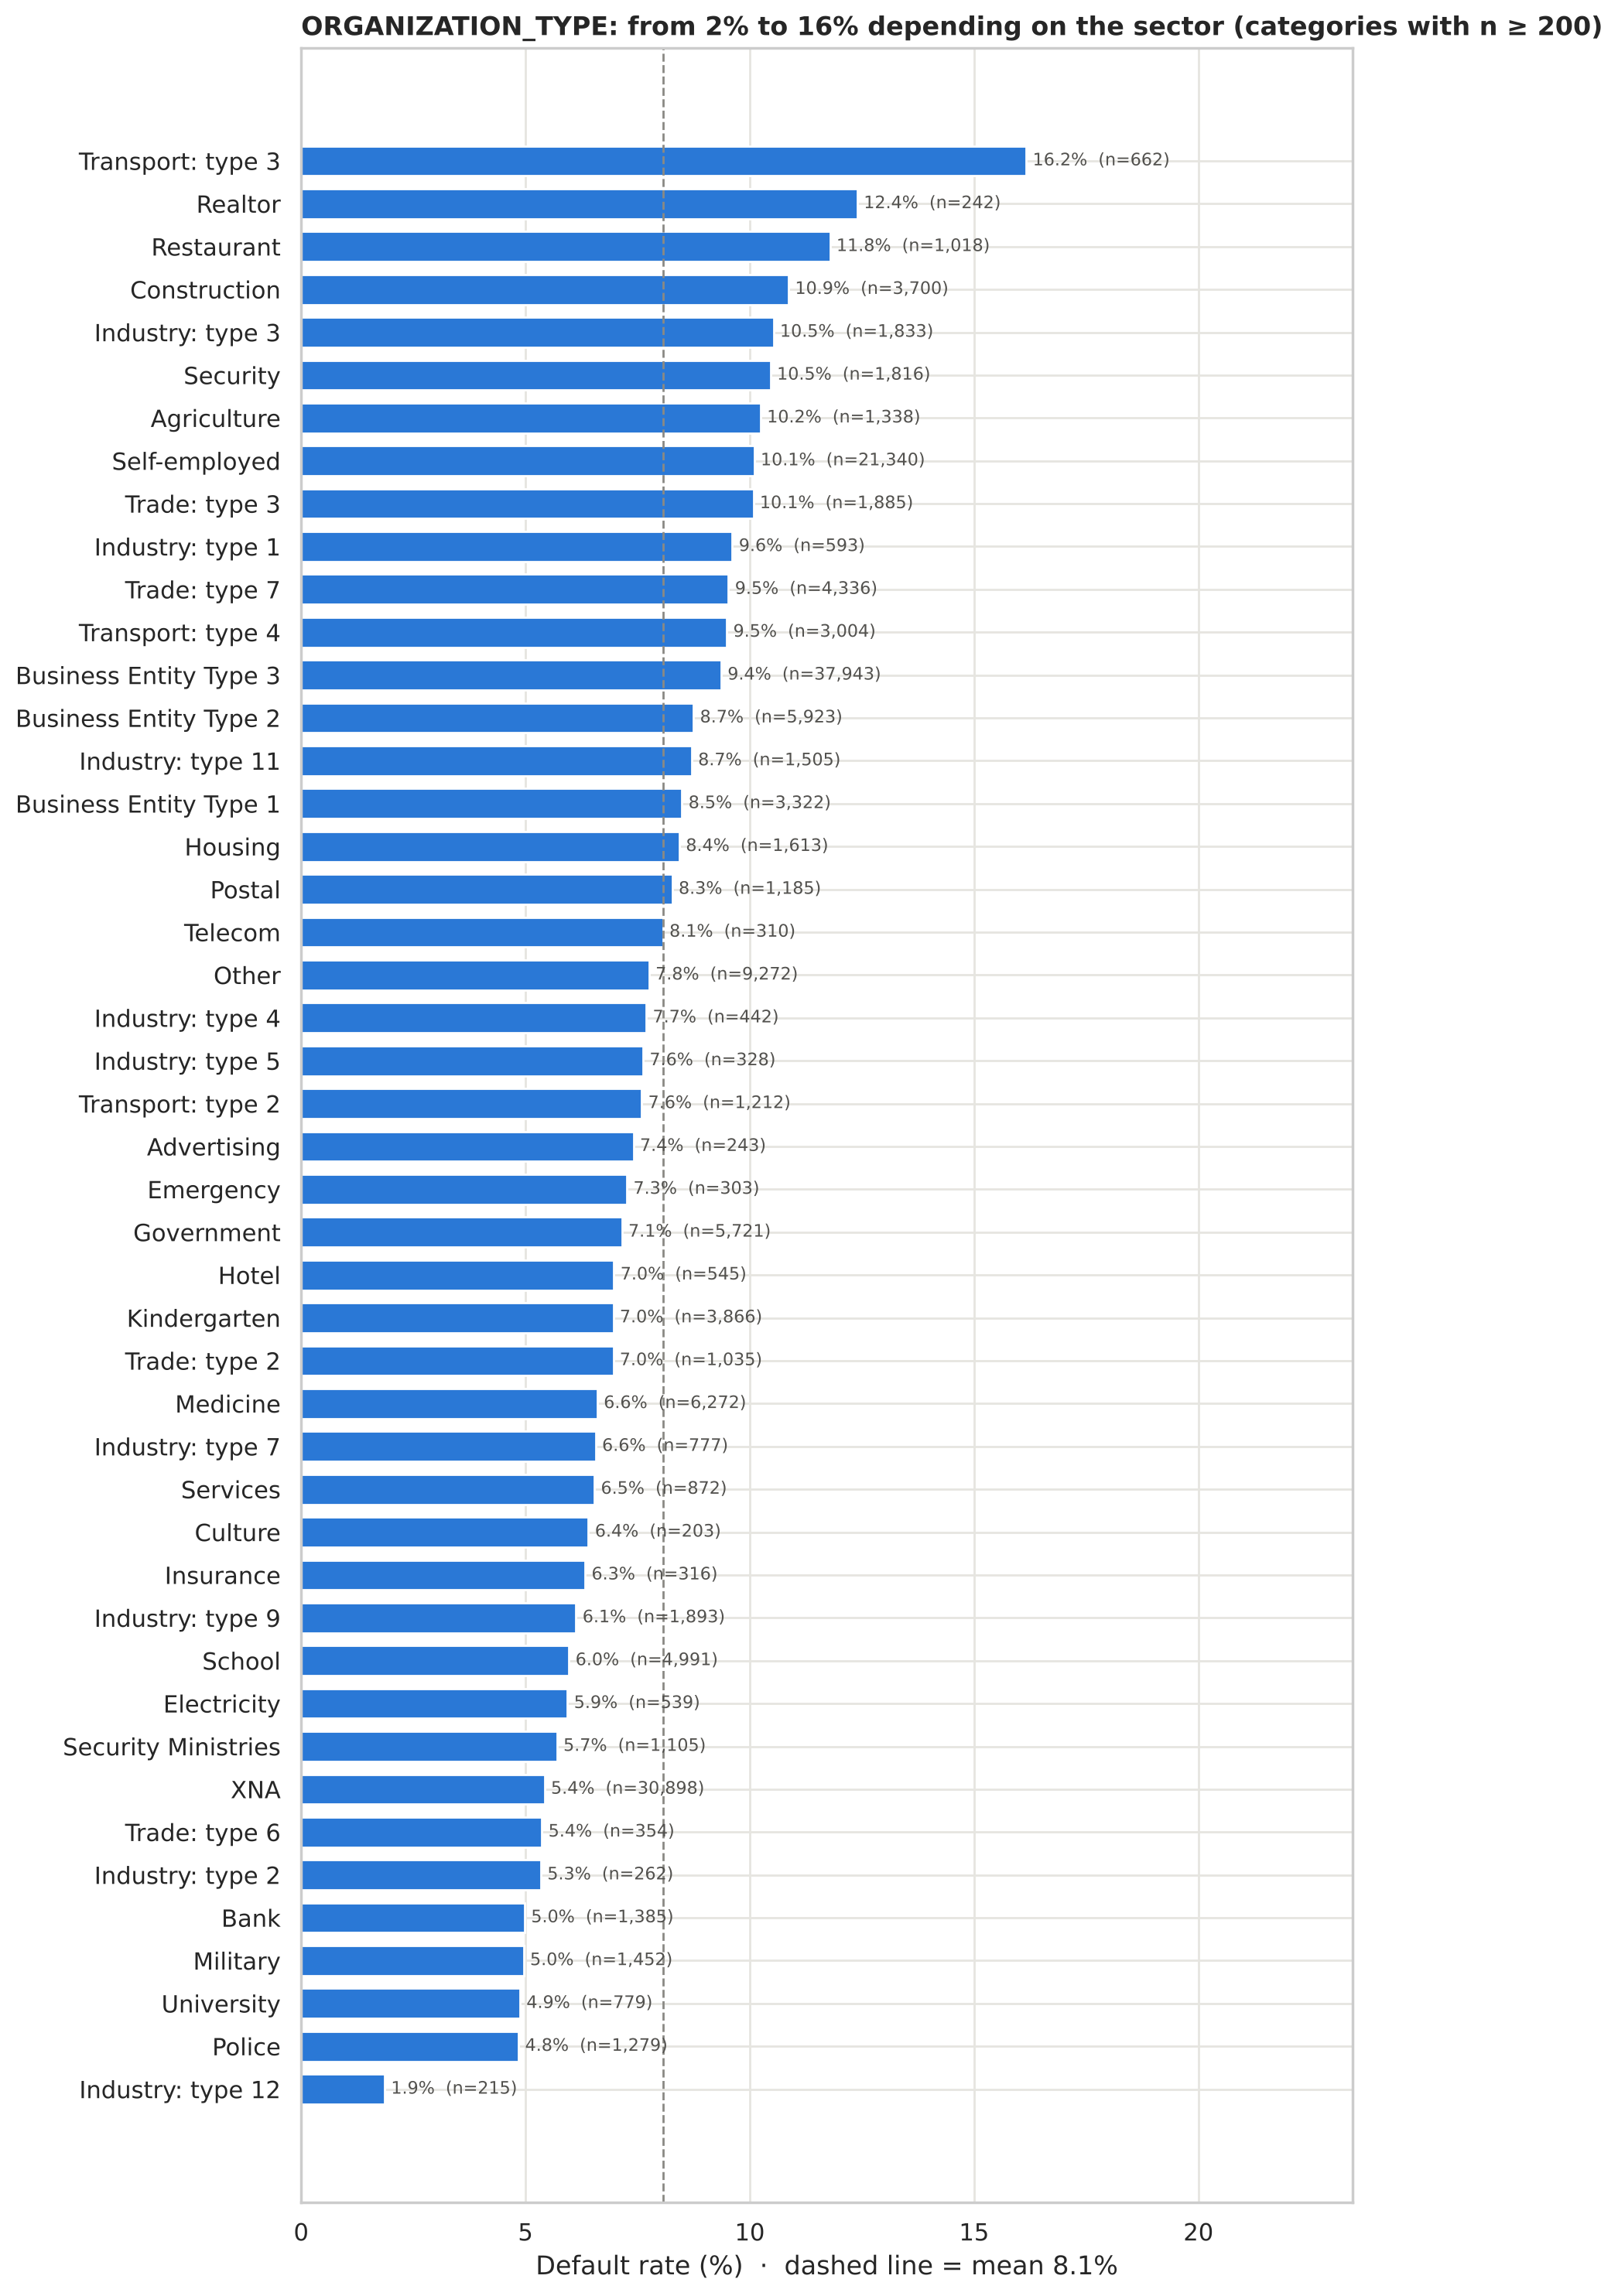

In [18]:
fig, ax = plt.subplots(figsize=(9, 15))
rate_bars("ORGANIZATION_TYPE", ax, min_n=200,
          title="ORGANIZATION_TYPE: from 2% to 16% depending on the sector (categories with n ≥ 200)")
plt.tight_layout(); plt.show()

**What we see:**
- `OCCUPATION_TYPE`: from 4.6% (accountants) to 16.2% (low-skill laborers). `Other` is the largest group (53,745 clients, 31%): in this dataset unknown occupations are grouped there rather than stored as `NaN`. It has its own rate (6.6%), so we keep it as a category.
- `ORGANIZATION_TYPE`: large differences between sectors. `XNA` (30,898 clients) are, once again, the pensioners: the same population as the `DAYS_EMPLOYED` anomaly.

**Decision (Phase 2):** try LightGBM's `category` type and **Count Encoding**. With 58 categories, Target Encoding could help, but it must be computed **inside each fold** so the `TARGET` does not leak (otherwise the model "cheats in the exam").

## 11. Binary flags

**Path in the tree:** categories, 2 per variable → **bars**.

FLAG_MOBIL
1    171201
0         1
Name: count, dtype: int64


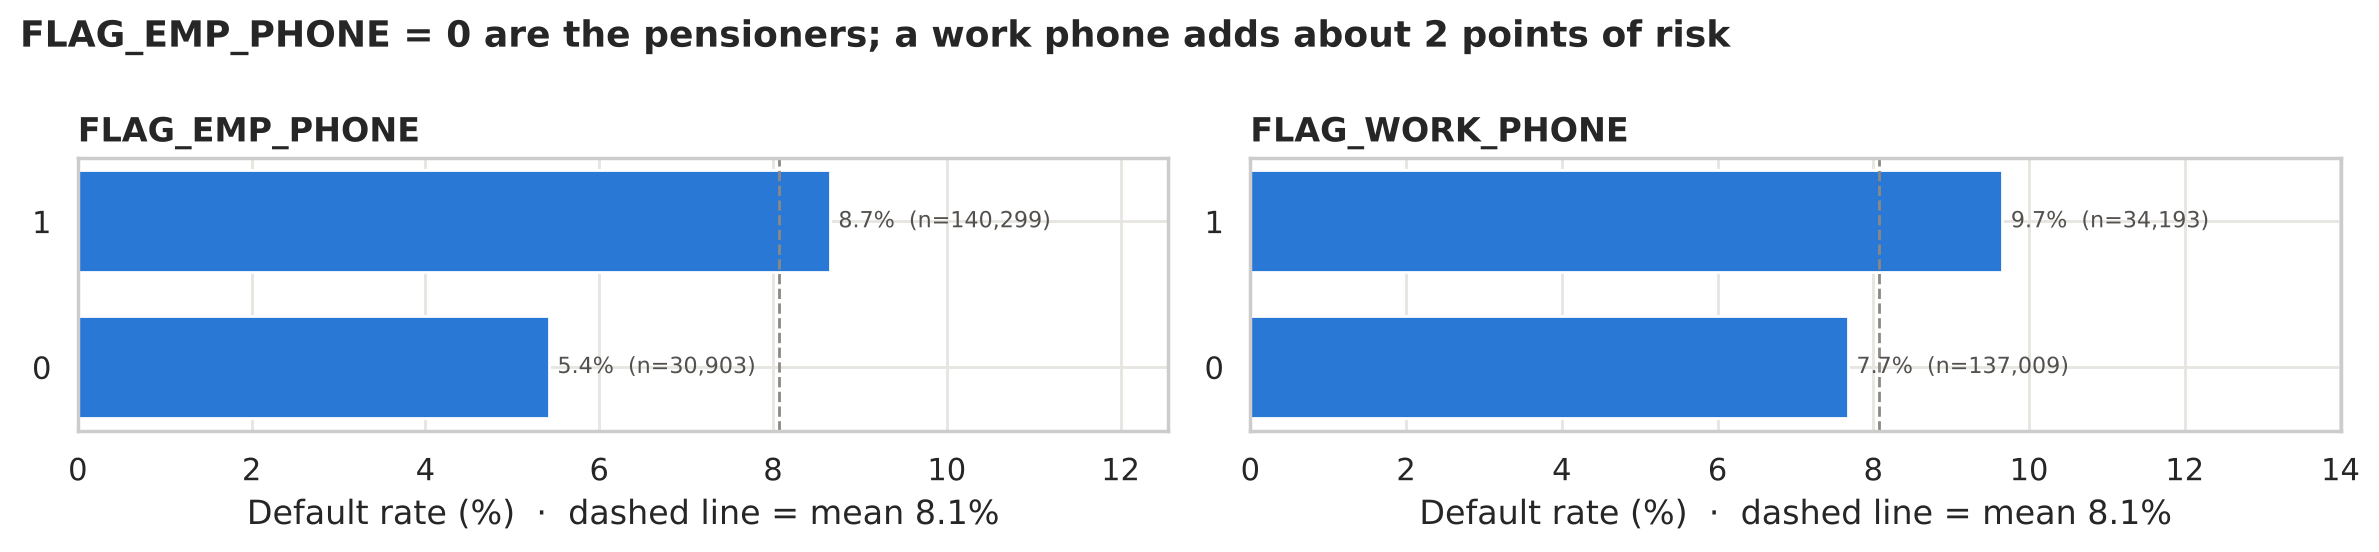

In [19]:
print(train["FLAG_MOBIL"].value_counts())
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
for ax, c in zip(axes, ["FLAG_EMP_PHONE", "FLAG_WORK_PHONE"]):
    rate_bars(c, ax, min_n=1)
fig.suptitle("FLAG_EMP_PHONE = 0 are the pensioners; a work phone adds about 2 points of risk",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**What we see:** `FLAG_MOBIL` is 1 for every client except one: it adds nothing. `FLAG_EMP_PHONE = 0` are the pensioners (see section 7).

**Decision (Phase 2):** drop `FLAG_MOBIL`.

## 12. Correlations between numeric variables

**Path in the tree:** compare many numeric variables with each other (more than 3)? **Yes** → only the strength of the relationship? **Yes** → **heatmap**. Diverging palette centred at 0 (blue negative, grey zero, red positive) and a fixed scale from -1 to 1. Only the lower triangle is shown because the upper one is its mirror image.

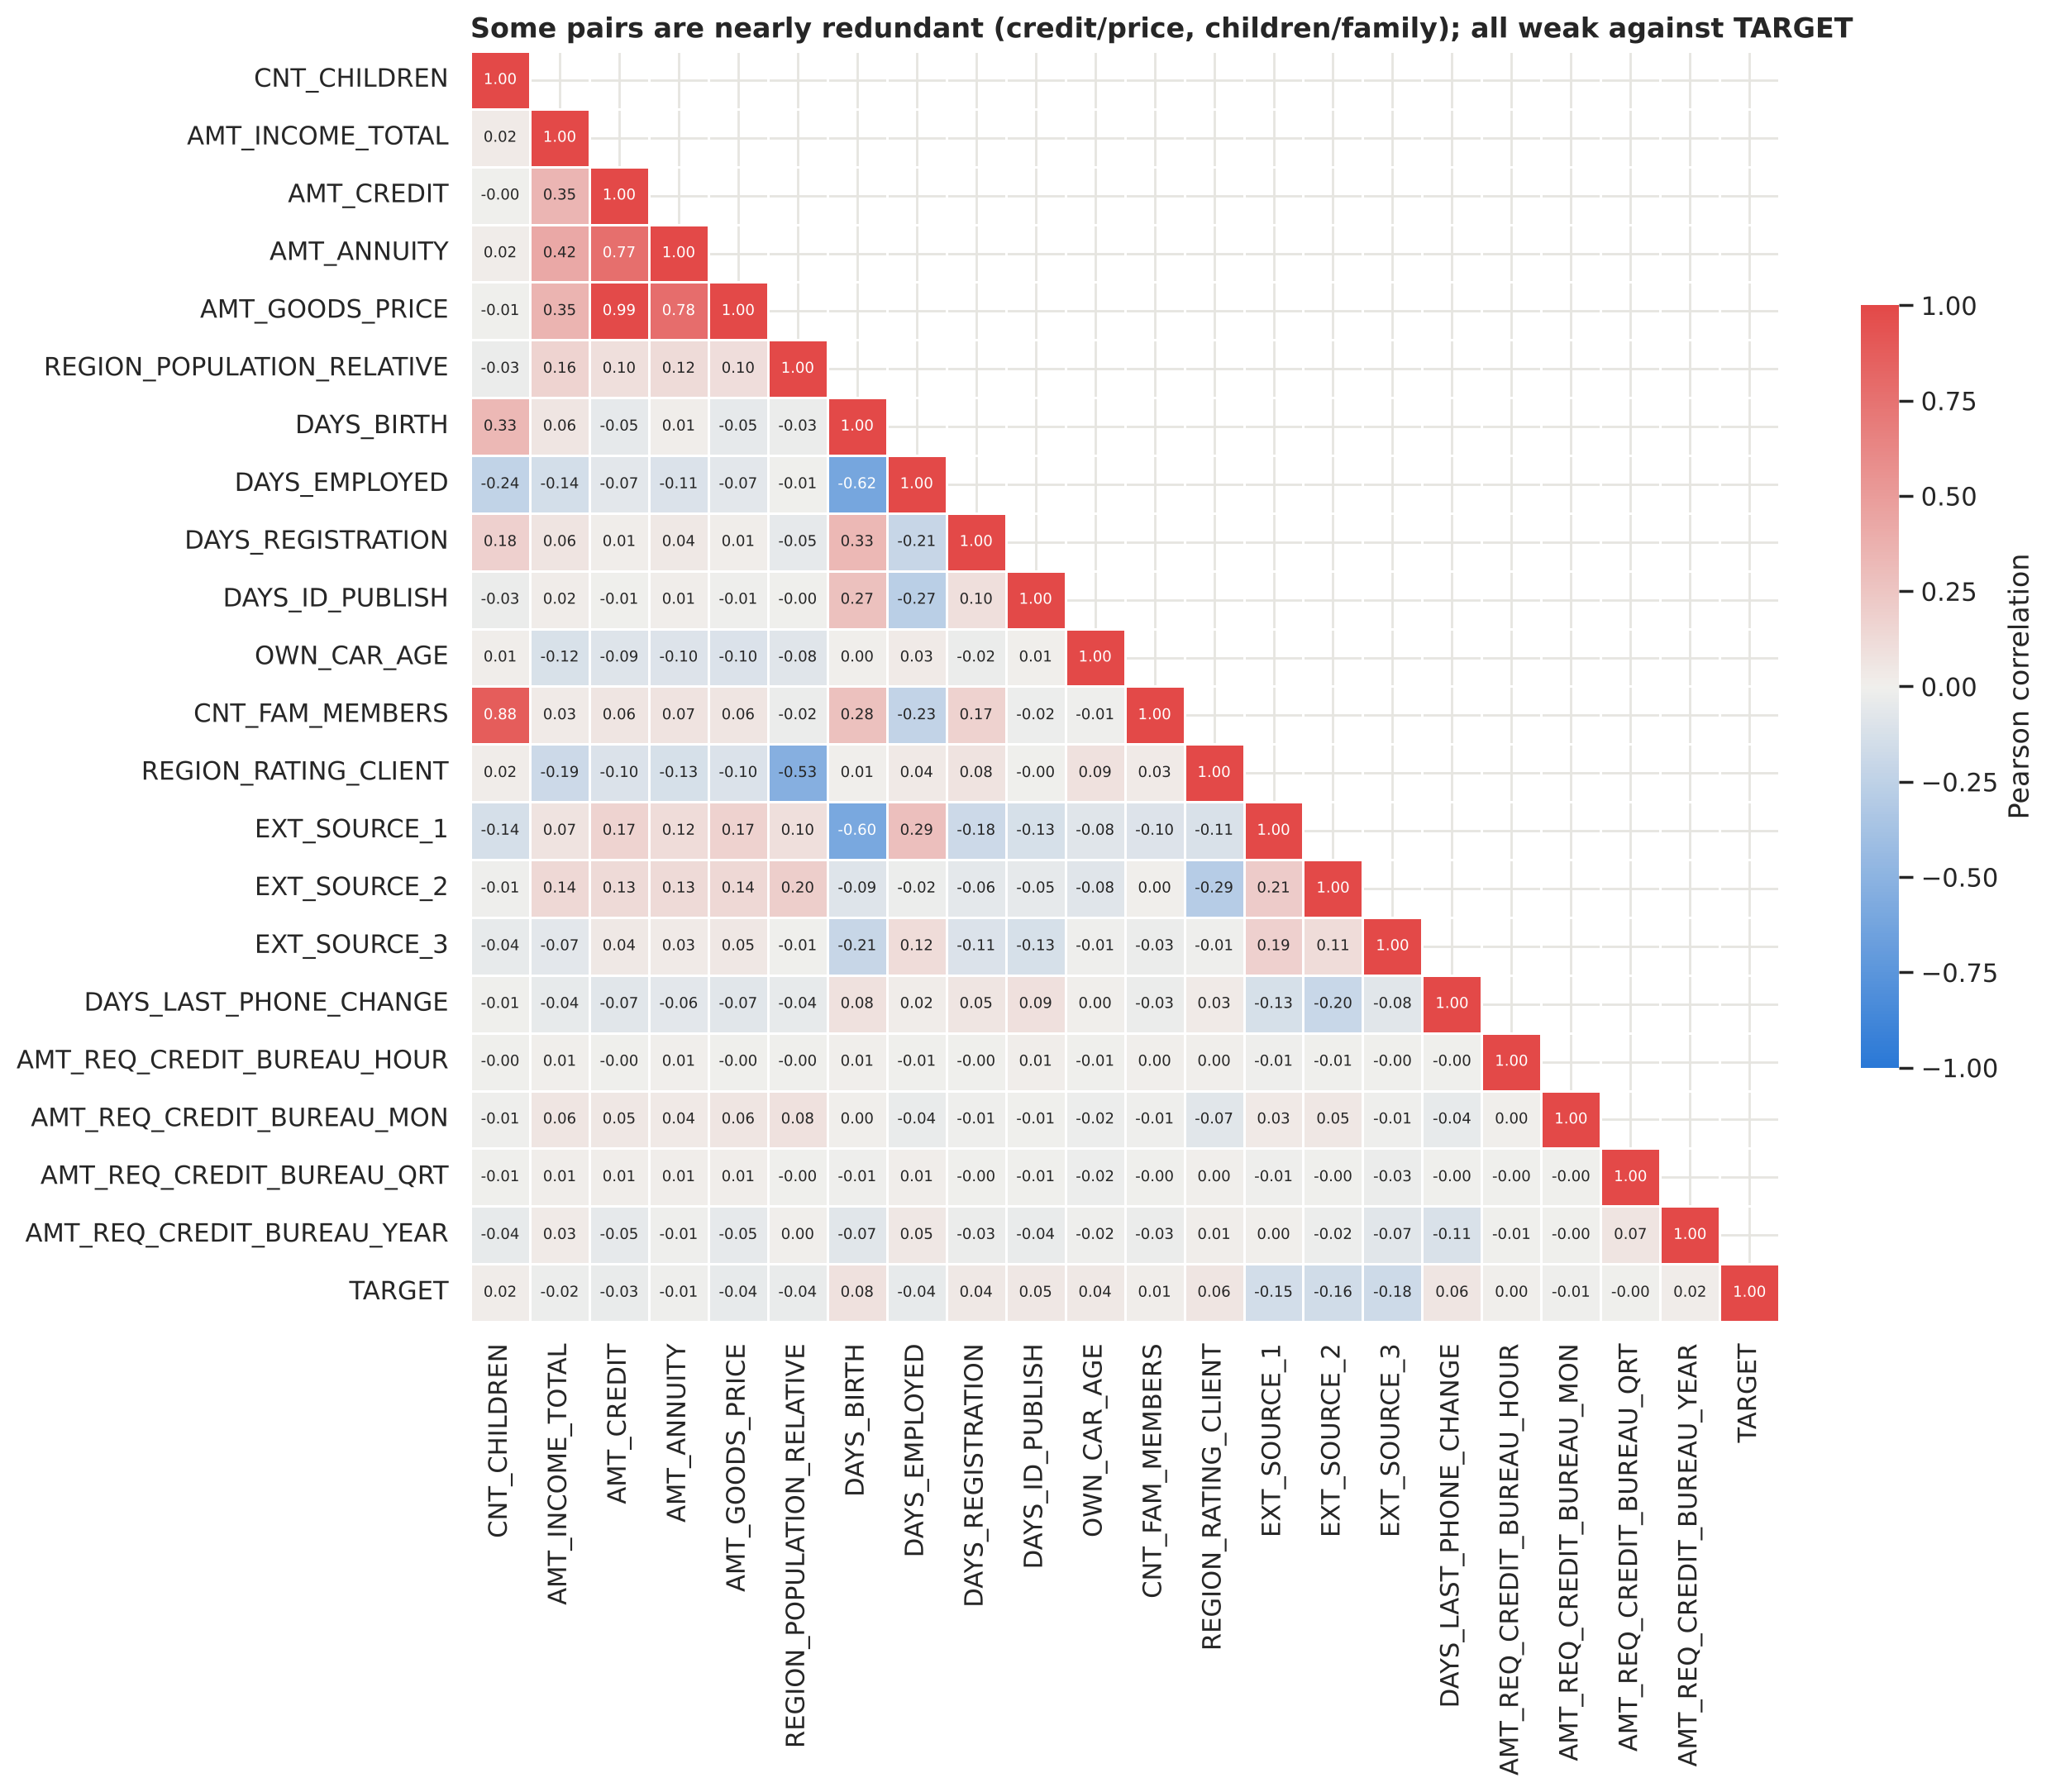

In [20]:
corr = train[num_cols + ["TARGET"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, cmap=CMAP_DIV, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 6.5}, linewidths=0.5, linecolor="white",
            cbar_kws={"shrink": 0.6, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Some pairs are nearly redundant (credit/price, children/family); all weak against TARGET")
plt.tight_layout(); plt.show()

**What we see:**
- **Nearly redundant pairs:** `AMT_CREDIT` ↔ `AMT_GOODS_PRICE` (0.99); `CNT_CHILDREN` ↔ `CNT_FAM_MEMBERS` (0.88); `AMT_ANNUITY` with the other amounts (~0.77).
- **The anomaly trap:** `DAYS_EMPLOYED` shows -0.62 against `DAYS_BIRTH`. If we remove the 365243 code, the correlation becomes **+0.35**: the code even flips the sign. One more reason to turn it into `NaN` in Phase 2.
- `EXT_SOURCE_1` is closely linked to age (-0.60 with `DAYS_BIRTH`, i.e. older clients get better scores).
- **TARGET row:** all correlations are small (the largest, the `EXT_SOURCE` scores, around -0.15 to -0.18). This is normal in credit risk: no single variable explains it, which is why we need a model that combines many.

**Decision:** do not drop correlated variables for LightGBM (they do not hurt it), but use them to build ratios.

## 13. Do train and test look alike?

If the exam (test) covered a different syllabus from the practice exams (train), studying with train would not help. We check by overlaying the distributions.

**Path in the tree:** distribution of one numeric variable → compare it across groups (train/test) → need to read percentiles? **Yes** → **ECDF**. If the two curves overlap, the distributions are the same. The ECDF also does not depend on bins and is not affected by the different sizes of train and test.

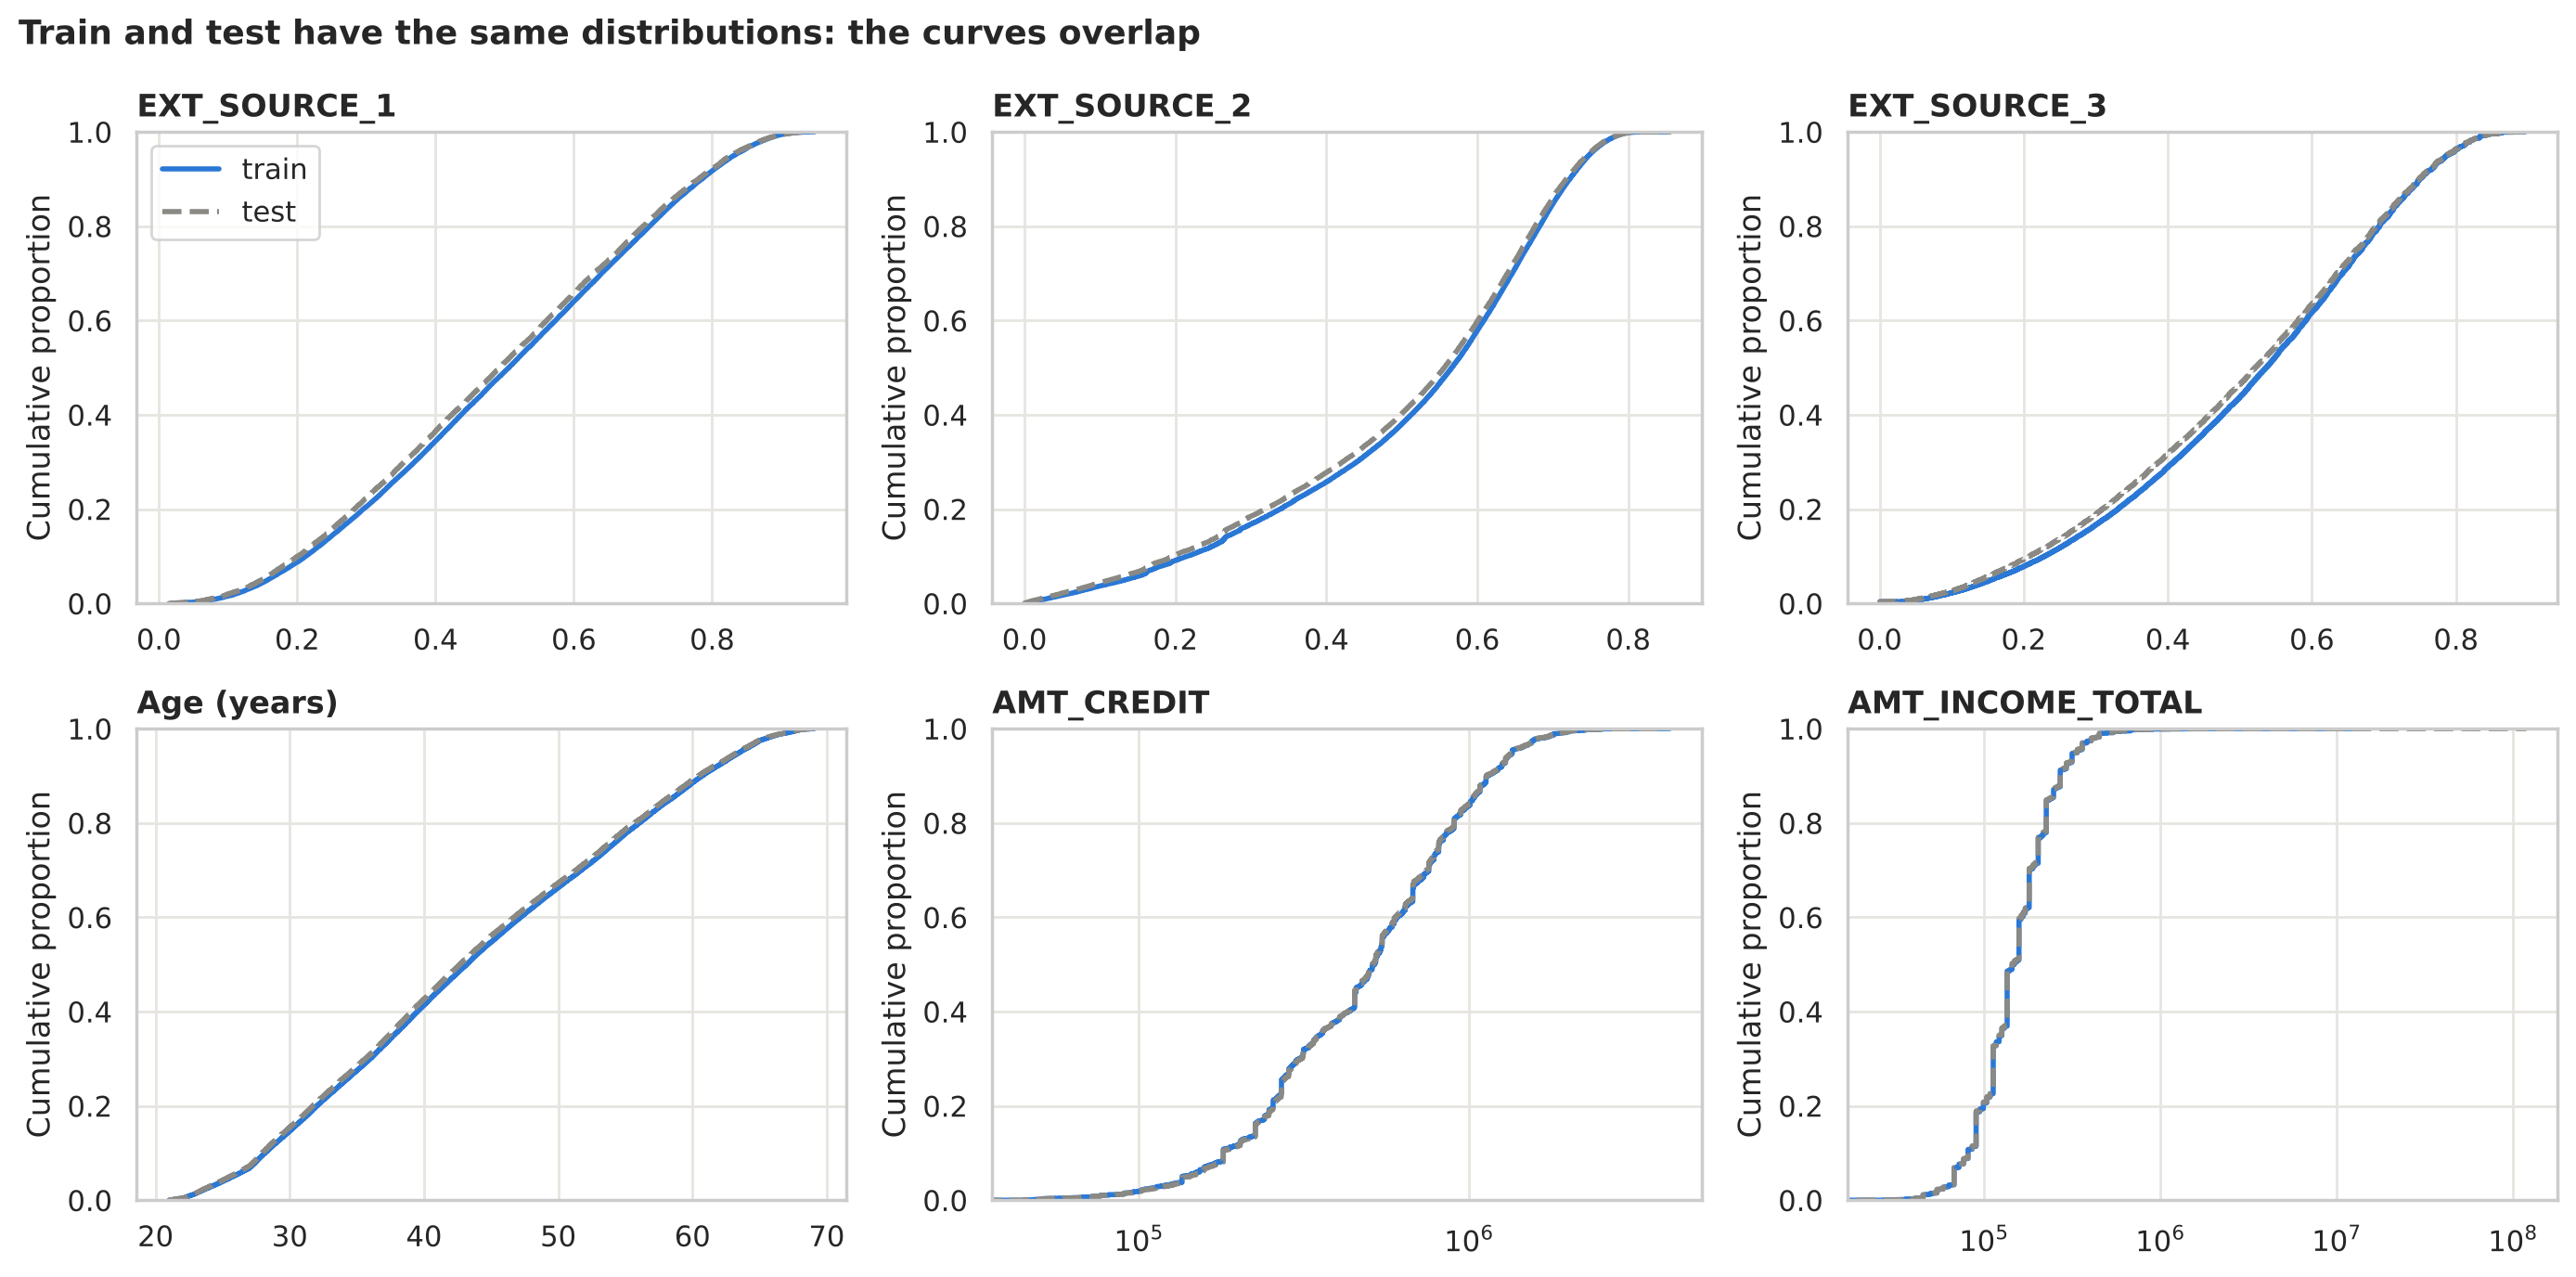

In [21]:
comp = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH", "AMT_CREDIT", "AMT_INCOME_TOTAL"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), comp):
    f = (lambda x: -x / 365.25) if c == "DAYS_BIRTH" else (lambda x: x)   # age in years
    sns.ecdfplot(f(train[c]), ax=ax, color=C_ONE, lw=2, label="train")
    sns.ecdfplot(f(test[c]), ax=ax, color=C_GREY, lw=2, ls="--", label="test")
    if c.startswith("AMT"):
        ax.set_xscale("log")
    ax.set_title("Age (years)" if c == "DAYS_BIRTH" else c); ax.set_xlabel(""); ax.set_ylabel("Cumulative proportion")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Train and test have the same distributions: the curves overlap",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**What we see:** the train and test curves are practically identical, as were the missing-value percentages (section 3). One exception to keep an eye on: test contains a client with an income of **117 million**, far above the train maximum (13.5 million); that is why the `AMT_INCOME_TOTAL` axis reaches 10⁸. LightGBM is not affected (it treats it as "the highest value"), but a ratio such as `CREDIT_INCOME_RATIO` will get an extreme value for that client.

**Decision:** we can trust cross-validation as an estimate of the test score.

## 14. Summary: from EDA to decisions

| # | Finding | Decision | Phase |
|---|---|---|---|
| 1 | Only 8.1% defaults | AUC + `StratifiedKFold`; never accuracy | 4 |
| 2 | `EXT_SOURCE_1/2/3` are the strongest variables (AUC 0.66-0.68) | Combinations: mean, min, max, std, product | 3 |
| 3 | A missing value raises the risk | Do not impute with the mean; `N_MISSING`, `EXT_SOURCE_N_MISSING` | 2-3 |
| 4 | Risk falls with age (11.7% → 4.8%) | `AGE_YEARS`, `EMPLOYED_BIRTH_RATIO` | 3 |
| 5 | `DAYS_EMPLOYED = 365243` = pensioners (18%) | → `NaN` + flag `DAYS_EMPLOYED_ANOM` | 2 |
| 6 | `FLAG_EMP_PHONE` repeats the anomaly above | Try dropping it | 2 |
| 7 | `OWN_CAR_AGE` = 64/65 are codes (1,825 rows) | → `NaN` + flag; keep as a number | 2 |
| 8 | Amounts alone do not separate; credit ≈ price (r 0.99) | Ratios credit/income, annuity/income, term, price/credit | 3 |
| 9 | Education, housing, income type, occupation and sector move the risk | LightGBM `category`; Count Encoding; Target Encoding only inside the fold | 2 |
| 10 | `"XNA"`, `"Unknown"`, categories with < 10 clients | → `NaN` | 2 |
| 11 | `FLAG_MOBIL` is constant | Drop it | 2 |
| 12 | Train and test share the same distribution (except one 117 M income in test) | Trust cross-validation | 4 |